# Лабораторная работа 1 - рабочий ноутбук

**ФИО:** Юхо Анна Викторовна  
**Файлы данных:** clients.csv, transactions.csv

Этот ноутбук - чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой - напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

CLIENTS_PATH = "clients.csv"
TXN_PATH = "transactions.csv"

LOG_COLUMNS = [
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
]
cleaning_log = pd.DataFrame(columns=LOG_COLUMNS)

def add_log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    """Добавляет одно решение в журнал без дублей при повторном запуске ячейки."""
    duplicate = (cleaning_log["field"] == field) & (cleaning_log["issue"] == issue)
    if not duplicate.any():
        cleaning_log.loc[len(cleaning_log)] = [
            field, issue, scope, int(n_rows), value_before, action, value_after, rationale
        ]

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [2]:
RAW_TXN = pd.read_csv(
    TXN_PATH, encoding="cp1251",
    sep=';',decimal=',',
    dtype={
        'txn_id': 'string',
        'client_id': 'string',
        'mcc_code': 'string'
    }
)
display(RAW_TXN.head())

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990058,C004548,2023-12-03 16:37:58,65.93,RUB,Транспорт,4111,Карта,успешно
1,990100,C001717,2023-12-12 17:32:54,546.10,RUB,Продукты,5411,Карта,успешно
2,100001,C003167,2024-01-01 00:30:43,383.82,RUB,Связь и Интернет,4814,Карта,успешно
3,100002,C001173,2024-01-01 01:24:06,88.41,RUB,Транспорт,4111,Карта,успешно
4,100003,C003581,2024-01-01 02:17:02,5738.06,RUB,Одежда и обувь,5651,Карта,успешно


In [3]:
RAW_CLIENTS = pd.read_csv(
    CLIENTS_PATH, encoding="utf-8",
    dtype={
        'client_id': 'string',
        'branch_code': 'string'
    }
)
display(RAW_CLIENTS.head())

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C002167,1974-02-10,М,Москва,Массовый,Базовый,Дебетовая,05.11.2024,03.12.2024,Зарплата в другом банке,50800.0,Да,2024-11,2.0,00402,Да
1,C003936,1970-02-16,Ж,Москва,Зарплатный,Серебро,Кредитная,01.06.2014,19.06.2018,Зарплата в нашем банке,47900.0,Нет,NaN,NaN,00156,Да
2,C002330,1937-07-11,Ж,Санкт-Петербург,Зарплатный,Золото,Кредитная,10.10.2019,09.11.2021,Зарплата в нашем банке,169100.0,Да,2024-11,5.0,00710,Да
3,C000981,1971-12-28,М,Новосибирск,Массовый,Серебро,Дебетовая,28.04.2016,05.12.2019,Зарплата в другом банке,34400.0,Да,2024-03,NaN,00911,Да
4,C001633,1980-01-13,Ж,Москва,Премиальный,Золото,Дебетовая,05.11.2018,03.07.2020,Зарплата в другом банке,214300.0,Да,2024-10,5.0,00777,Да


In [4]:
n_client_dates = len(RAW_CLIENTS)
n_app_dates = RAW_CLIENTS['app_last_login'].notna().sum()
n_txn_dates = RAW_TXN['txn_datetime'].notna().sum()

RAW_CLIENTS['birth_date'] = pd.to_datetime(
    RAW_CLIENTS['birth_date'],format='%Y-%m-%d',errors='coerce'
)
for col in ['registration_date', 'card_open_date']:
    RAW_CLIENTS[col] = pd.to_datetime(
        RAW_CLIENTS[col],format='%d.%m.%Y',errors='coerce'
    )

RAW_CLIENTS['app_last_login'] = pd.to_datetime(
    RAW_CLIENTS['app_last_login'],format='%Y-%m',errors='coerce'
)
txn_datetime_raw = RAW_TXN["txn_datetime"].astype("string")
txn_has_time = txn_datetime_raw.str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}")
txn_date_only = txn_datetime_raw.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
assert (txn_has_time | txn_date_only).all()
parsed_txn_datetime = pd.Series(pd.NaT, index=RAW_TXN.index, dtype="datetime64[ns]")
parsed_txn_datetime.loc[txn_has_time] = pd.to_datetime(
    txn_datetime_raw.loc[txn_has_time], format="%Y-%m-%d %H:%M:%S", errors="raise"
)
parsed_txn_datetime.loc[txn_date_only] = pd.to_datetime(
    txn_datetime_raw.loc[txn_date_only], format="%Y-%m-%d", errors="raise"
)
RAW_TXN["txn_datetime"] = parsed_txn_datetime

add_log(
    "birth_date, registration_date, card_open_date", "Даты представлены текстом",
    "Все строки таблицы клиентов", n_client_dates, "Текстовые даты",
    "Преобразовано в datetime", "datetime64[ns]",
    "Для сравнения дат и расчёта возраста и стажа клиента"
)
add_log(
    "app_last_login", "Последний вход указан с точностью до месяца",
    "Строки с заполненным app_last_login", n_app_dates, "Год и месяц",
    "Преобразовано в datetime", "Дата с первым числом месяца",
    "Добавленный день не является фактическим днём входа"
)
add_log(
    "txn_datetime", "Разные форматы: дата со временем и без времени",
    "Строки с заполненным txn_datetime", n_txn_dates,
    "574754 дат со временем и 49646 дат без времени",
    "Оба обнаруженных формата разобраны отдельно и явно",
    "datetime64[ns]; даты без времени получили 00:00:00",
    "Явные форматы исключают неоднозначный автоматический парсинг; точное время известно не для всех операций"
)

In [5]:
display(RAW_CLIENTS.head())

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C002167,1974-02-10,М,Москва,Массовый,Базовый,Дебетовая,2024-11-05,2024-12-03,Зарплата в другом банке,50800.0,Да,2024-11-01,2.0,00402,Да
1,C003936,1970-02-16,Ж,Москва,Зарплатный,Серебро,Кредитная,2014-06-01,2018-06-19,Зарплата в нашем банке,47900.0,Нет,NaT,NaN,00156,Да
2,C002330,1937-07-11,Ж,Санкт-Петербург,Зарплатный,Золото,Кредитная,2019-10-10,2021-11-09,Зарплата в нашем банке,169100.0,Да,2024-11-01,5.0,00710,Да
3,C000981,1971-12-28,М,Новосибирск,Массовый,Серебро,Дебетовая,2016-04-28,2019-12-05,Зарплата в другом банке,34400.0,Да,2024-03-01,NaN,00911,Да
4,C001633,1980-01-13,Ж,Москва,Премиальный,Золото,Дебетовая,2018-11-05,2020-07-03,Зарплата в другом банке,214300.0,Да,2024-10-01,5.0,00777,Да


In [6]:
display(RAW_TXN.head(15))

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990058,C004548,2023-12-03 16:37:58,65.93,RUB,Транспорт,4111,Карта,успешно
1,990100,C001717,2023-12-12 17:32:54,546.10,RUB,Продукты,5411,Карта,успешно
2,100001,C003167,2024-01-01 00:30:43,383.82,RUB,Связь и Интернет,4814,Карта,успешно
3,100002,C001173,2024-01-01 01:24:06,88.41,RUB,Транспорт,4111,Карта,успешно
4,100003,C003581,2024-01-01 02:17:02,5738.06,RUB,Одежда и обувь,5651,Карта,успешно
5,100004,C004183,2024-01-01 02:24:04,511.27,RUB,Связь и Интернет,4814,Карта,успешно
6,100005,C003058,2024-01-01 02:56:56,405.50,RUB,Кафе и рестораны,5812,Карта,успешно
7,100006,C004736,2024-01-01 03:29:12,1384.21,RUB,Продукты,5411,СБП,успешно
8,100007,C002491,2024-01-01 04:08:36,1019.79,RUB,АЗС,5541,Карта,успешно
9,100008,C000460,2024-01-01 04:16:07,290.91,RUB,Продукты,5411,Карта,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете - только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [7]:
RAW_CLIENTS.shape

(5730, 16)

In [8]:
RAW_TXN.shape

(624400, 9)

In [9]:
RAW_CLIENTS.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5730 entries, 0 to 5729
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5730 non-null   string        
 1   birth_date          5730 non-null   datetime64[ns]
 2   gender              5730 non-null   object        
 3   city                5730 non-null   object        
 4   segment             5730 non-null   object        
 5   loyalty_tier        5730 non-null   object        
 6   card_type           5730 non-null   object        
 7   registration_date   5730 non-null   datetime64[ns]
 8   card_open_date      5730 non-null   datetime64[ns]
 9   income_source       5730 non-null   object        
 10  monthly_income      5205 non-null   float64       
 11  has_mobile_app      5730 non-null   object        
 12  app_last_login      3508 non-null   datetime64[ns]
 13  satisfaction_score  2308 non-null   float64     

In [10]:
RAW_TXN.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 624400 entries, 0 to 624399
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        624400 non-null  string        
 1   client_id     624400 non-null  string        
 2   txn_datetime  624400 non-null  datetime64[ns]
 3   amount        624400 non-null  float64       
 4   currency      624400 non-null  object        
 5   category      624400 non-null  object        
 6   mcc_code      624400 non-null  string        
 7   channel       624400 non-null  object        
 8   status        624400 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(4), string(3)
memory usage: 42.9+ MB


In [11]:
RAW_CLIENTS["client_id"].isna().sum()

0

In [12]:
RAW_TXN["txn_id"].isna().sum()

0

In [13]:
RAW_CLIENTS["client_id"].is_unique

False

In [14]:
RAW_TXN["txn_id"].is_unique

False

### 2.2. Дубли

In [15]:
RAW_CLIENTS.duplicated().sum()

40

In [16]:
RAW_CLIENTS.duplicated("client_id").sum()

55

In [17]:
RAW_TXN.duplicated().sum()

1304

In [18]:
RAW_TXN.duplicated("txn_id").sum()

1500

In [19]:
RAW_CLIENTS.duplicated().mean() * 100

0.6980802792321117

In [20]:
RAW_TXN.duplicated().mean() * 100

0.2088404868673927

### 2.3. Соответствие данных описанию полей из задания

In [21]:
RAW_CLIENTS.isna().sum()

client_id                0
birth_date               0
gender                   0
city                     0
segment                  0
loyalty_tier             0
card_type                0
registration_date        0
card_open_date           0
income_source            0
monthly_income         525
has_mobile_app           0
app_last_login        2222
satisfaction_score    3422
branch_code              0
marketing_opt_in         0
dtype: int64

In [22]:
RAW_TXN.isna().sum()

txn_id          0
client_id       0
txn_datetime    0
amount          0
currency        0
category        0
mcc_code        0
channel         0
status          0
dtype: int64

In [23]:
(RAW_CLIENTS["segment"].notna() & ~RAW_CLIENTS["segment"].isin(["Массовый", "Зарплатный", "Премиальный", "Private"])).sum()

0

In [24]:
(RAW_CLIENTS["loyalty_tier"].notna()& ~RAW_CLIENTS["loyalty_tier"].isin(["Базовый", "Серебро", "Золото", "Платина"])).sum()


0

In [25]:
(RAW_CLIENTS["card_type"].notna()& ~RAW_CLIENTS["card_type"].isin(["Дебетовая", "Кредитная", "Премиальная"])).sum()

0

In [26]:
(RAW_CLIENTS["registration_date"] < RAW_CLIENTS["birth_date"]).sum()

0

In [27]:
(RAW_CLIENTS["card_open_date"] < RAW_CLIENTS["registration_date"]).sum()

0

In [28]:
(RAW_CLIENTS["birth_date"]>"2008-01-01").sum()

0

In [29]:
((RAW_CLIENTS["birth_date"] < "1906-01-01") |(RAW_CLIENTS["birth_date"] >= "2008-01-01")).sum()

0

In [30]:
(RAW_CLIENTS["monthly_income"] < 0).sum()

60

In [31]:
(RAW_CLIENTS["satisfaction_score"].notna() & ~RAW_CLIENTS["satisfaction_score"].between(1, 5)).sum()

0

In [32]:
RAW_CLIENTS["city"].unique()

array(['Москва', 'Санкт-Петербург', 'Новосибирск', 'Казань',
       'Екатеринбург', 'Н. Новгород', 'Нижний Новгород', 'МОСКВА',
       ' москва', 'г. Москва', 'г. Новосибирск', 'г. Санкт-Петербург',
       'казань', 'СПб', 'ЕКАТЕРИНБУРГ', 'Санкт Петербург',
       'г.Екатеринбург'], dtype=object)

In [33]:
(RAW_TXN["channel"].notna()& ~RAW_TXN["channel"].isin(["Карта", "Токен", "СБП","Онлайн-банк"])).sum()

0

In [34]:
(RAW_TXN["status"].notna()& ~RAW_TXN["status"].isin(["успешно", "отклонено", "возврат"])).sum()

0

In [35]:
RAW_TXN["category"].unique()

array(['Транспорт', 'Продукты', 'Связь и Интернет', 'Одежда и обувь',
       'Кафе и рестораны', 'АЗС', 'Онлайн-сервисы', 'кафе и рестораны',
       'Аптеки', 'Развлечения и досуг', 'Кафе/рестораны',
       'Связь и интернет'], dtype=object)

In [36]:
RAW_TXN["mcc_code"].unique()

<StringArray>
['4111', '5411', '4814', '5651', '5812', '5541', '5815', '5912', '7832']
Length: 9, dtype: string

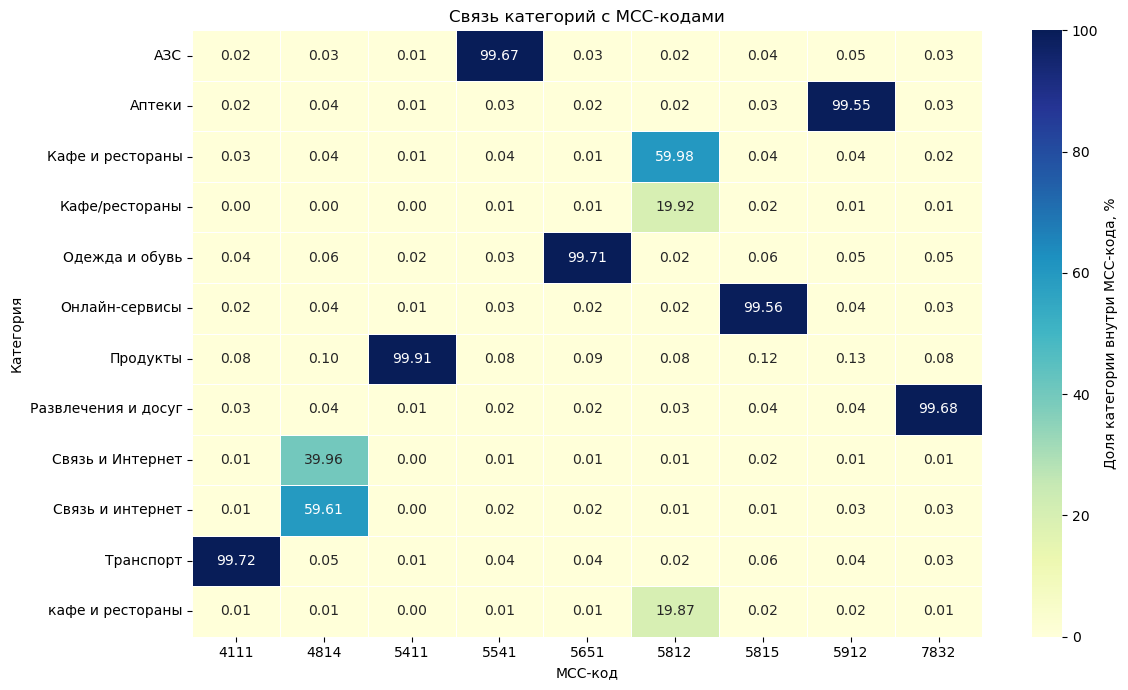

In [37]:
category_within_mcc = (
    pd.crosstab(
        RAW_TXN["category"],
        RAW_TXN["mcc_code"],
        normalize="columns",
    )
    .mul(100)
    .round(2)
)

plt.figure(figsize=(12, 7))
sns.heatmap(
    category_within_mcc,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Доля категории внутри MCC-кода, %"},
)
plt.title("Связь категорий с MCC-кодами")
plt.xlabel("MCC-код")
plt.ylabel("Категория")
plt.tight_layout()
plt.show()

In [38]:
((RAW_TXN["txn_datetime"] < "2024-01-01") |(RAW_TXN["txn_datetime"] >= "2025-07-01")).sum()

84

In [39]:
(RAW_TXN["amount"] == 0).sum()

0

In [40]:
(RAW_TXN["amount"] < 0).sum()

7432

In [41]:
RAW_TXN.loc[RAW_TXN["amount"] < 0, "status"].value_counts(dropna=False)

status
возврат    7432
Name: count, dtype: int64

In [42]:
(RAW_TXN["status"] == "возврат").sum()

7432

In [43]:
RAW_CLIENTS["gender"].value_counts()

gender
М    2894
Ж    2836
Name: count, dtype: int64

In [44]:
RAW_CLIENTS["branch_code"].value_counts()

branch_code
00706    17
00611    16
00371    16
00710    15
00749    15
         ..
00533     1
00206     1
00318     1
00849     1
00212     1
Name: count, Length: 839, dtype: Int64

In [45]:
RAW_CLIENTS["has_mobile_app"].value_counts()

has_mobile_app
Да     3508
Нет    2222
Name: count, dtype: int64

In [46]:
RAW_CLIENTS["marketing_opt_in"].value_counts()

marketing_opt_in
Да     5032
Нет     698
Name: count, dtype: int64

In [47]:
RAW_TXN["currency"].value_counts()

currency
RUB    621935
USD      1261
EUR      1204
Name: count, dtype: int64

In [48]:
RAW_CLIENTS["satisfaction_score"].value_counts()

satisfaction_score
5.0    645
3.0    465
2.0    464
4.0    446
1.0    288
Name: count, dtype: int64

### 2.4. Связь между таблицами

# Таблицы связаны по столбцу client_id

In [49]:
(~RAW_TXN["client_id"].isin(RAW_CLIENTS["client_id"])).sum()

28167

In [50]:
(~RAW_TXN["client_id"].isin(RAW_CLIENTS["client_id"])).mean() * 100

4.511050608584241

In [51]:
RAW_CLIENTS.loc[~RAW_CLIENTS["client_id"].isin(RAW_TXN["client_id"]), "client_id"].nunique()

13

**Выводы по аудиту**

1. **Дубли.** В таблице клиентов 40 полных дублей, в таблице транзакций 1304 полных дублей
2. **Повторяющиеся идентификаторы.** 55 повторов client_id и 1500 повторов txn_id
3. **Города**. Разные написания одних и тех же городов
4. **Доход.** В monthly_income обнаружено 525 пропусков и 60 отрицательных значений. 
5. **Использование приложения.** В app_last_login обнаружено 2222 пропуска. Так же в has_mobile_app ответов "нет" 2222 поэтому количество пропусков объяснимо
6. **Возраст.** Все клиенты старше 18 лет, минимальный и максимальный возраст правдоподобны. При дальнейшем анализе отдельно проверено необычное скопление значений у верхней возрастной границы.
7. **Оценка обслуживания.** В satisfaction_score обнаружено 3422 пропуска, а там где нету пропуска все оценки в диапазоне соответствующему описанию
8. **Период операций.** Замечено 84 транзакции вне диапазона 01.01.2024-30.06.2025
9. **Категории и MCC-коды.** Обнаружено 12 названий категорий вместо девяти из-за разных написаний одних категорий. Также выявлена неоднозначность соответствия категорий и MCC-кодов: одни и те же коды встречаются в разных по смыслу категориях
10. **Связь таблиц.** Для 28 167 транзакций не найдено точного совпадения client_id в таблице клиентов. Эти операции нельзя связать с характеристиками клиентов и согласием на коммуникацию. Необходимо проверить наличие клиентов в выгрузке и формат идентификаторов.
11. **Сумма операций**. Обнаружено 7432 транзакций с отрицательным значением amount, но произведя проверку оказалось что все эти транзакции на возврат и всего возвратных транзакций так же 7432
12. **Согласие на коммуникацию.** Согласие дали 5 032 из 5 730 клиентов сырого справочника (87,8%); для кампании будут использоваться только такие клиенты.

## 3. Препроцессинг

На каждое изменение - строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

In [52]:
clients = RAW_CLIENTS.copy()
txn = RAW_TXN.copy()

In [53]:
negative_amount_mask = txn["amount"].lt(0)
return_mask = txn["status"].eq("возврат")
assert negative_amount_mask.equals(return_mask)
assert not (clients["registration_date"] < clients["birth_date"]).any()
assert not (clients["card_open_date"] < clients["registration_date"]).any()
add_log(
    "amount, status", "Отрицательные суммы требуют смысловой проверки",
    "Все строки с amount < 0", int(negative_amount_mask.sum()),
    "7432 отрицательные суммы; во всех строках status = 'возврат'",
    "Значения оставлены без исправления знака",
    "Отрицательная сумма сохранена как сумма возврата",
    "Совпадение масок amount < 0 и status = 'возврат' подтверждает бизнес-смысл знака",
)

In [54]:
n_client_duplicates = clients.duplicated().sum()
clients = clients.drop_duplicates()
add_log(
    "Все поля", "Полные дубли строк клиентов",
    "Таблица клиентов: полностью одинаковые строки", n_client_duplicates,
    "Одинаковые строки встречаются несколько раз", "Удалены полные дубли",
    "Сохранён один экземпляр каждой строки",
    "Исключить повторный учёт клиентов и размножение строк при объединении"
)

In [55]:
n_txn_duplicates = txn.duplicated().sum()
txn = txn.drop_duplicates()
add_log(
    "Все поля", "Полные дубли транзакций",
    "Таблица транзакций: полностью одинаковые строки", n_txn_duplicates,
    "Одинаковые строки встречаются несколько раз", "Удалены полные дубли",
    "Сохранён один экземпляр каждой строки",
    "Исключить завышение количества операций и сумм расходов"
)

### 3.1. Типы, даты, числа

Типы данных настроены при загрузке. Идентификаторы и коды прочитаны как строки, числовые поля прочитаны как числа с плавающей точкой. 

Для txn_datetime сначала проверены исходные шаблоны: 574 754 значения записаны как дата с временем, ещё 49 646 как дата без времени, для таких записей 00:00:00 является техническим заполнением, а не известным временем операции.

В app_last_login дата только с годом и месяцем. Добавленное первое число месяца не является фактическим днём входа.

### 3.2. Категориальные признаки

In [56]:
cities = {
    "Н. Новгород": "Нижний Новгород",
    "МОСКВА": "Москва",
    " москва": "Москва",
    "г. Москва": "Москва",
    "г. Новосибирск": "Новосибирск",
    "г. Санкт-Петербург": "Санкт-Петербург",
    "казань": "Казань",
    "СПб": "Санкт-Петербург",
    "ЕКАТЕРИНБУРГ": "Екатеринбург",
    "Санкт Петербург": "Санкт-Петербург",
    "г.Екатеринбург": "Екатеринбург"
}

In [57]:
n_city_replacements = clients["city"].isin(cities).sum()
clients["city"] = clients["city"].replace(cities)
add_log(
    "city", "Разные написания одинаковых городов",
    "Строки с названиями из словаря cities", n_city_replacements,
    "; ".join(cities.keys()), "Названия приведены к единому виду",
    "; ".join(sorted(set(cities.values()))),
    "Объединить записи одного города без изменения смысла"
)
n_city_replacements

1598

In [58]:
clients["city"].unique()

array(['Москва', 'Санкт-Петербург', 'Новосибирск', 'Казань',
       'Екатеринбург', 'Нижний Новгород'], dtype=object)

In [59]:
categories = {
    "кафе и рестораны": "Кафе и рестораны",
    "Кафе/рестораны": "Кафе и рестораны",
    "Связь и интернет": "Связь и Интернет"
}

In [60]:
n_category_replacements = txn["category"].isin(categories).sum()
txn["category"] = txn["category"].replace(categories)
add_log(
    "category", "Разные написания одинаковых категорий",
    "Строки с названиями из словаря categories", n_category_replacements,
    "; ".join(categories.keys()), "Названия приведены к единому виду",
    "; ".join(sorted(set(categories.values()))),
    "Чтобы расходы одной категории не разделялись между разными названиями"
)
n_category_replacements

61301

In [61]:
txn["category"].unique()

array(['Транспорт', 'Продукты', 'Связь и Интернет', 'Одежда и обувь',
       'Кафе и рестораны', 'АЗС', 'Онлайн-сервисы', 'Аптеки',
       'Развлечения и досуг'], dtype=object)

In [62]:
mcc_to_category = {
    "4111": "Транспорт",
    "4814": "Связь и Интернет",
    "5411": "Продукты",
    "5541": "АЗС",
    "5651": "Одежда и обувь",
    "5812": "Кафе и рестораны",
    "5815": "Онлайн-сервисы",
    "5912": "Аптеки",
    "7832": "Развлечения и досуг",
}

category_from_mcc = txn["mcc_code"].map(mcc_to_category)

category_comparison = pd.DataFrame({
    "По category": txn["category"].value_counts(),
    "По mcc_code": category_from_mcc.value_counts(),
}).fillna(0).astype(int)

category_comparison["Разница"] = (
    category_comparison["По mcc_code"] - category_comparison["По category"]
)

n_mcc_category_mismatch = int(txn["category"].ne(category_from_mcc).sum())

add_log(
    "category, mcc_code",
    "Одному MCC-коду соответствуют несколько категорий",
    "Строки, где category не совпадает с категорией MCC",
    n_mcc_category_mismatch,
    "category и mcc_code указывают на разные категории",
    "Оставлено без изменения",
    "Исходные category и mcc_code сохранены",
    "Нельзя определить ошибочное поле; остальные данные транзакции остаются полезными",
)

display(category_comparison)

,По category,По mcc_code,Разница
Продукты,163935,163652,-283
Кафе и рестораны,80943,80908,-35
Одежда и обувь,64747,64745,-2
Транспорт,64703,64719,16
АЗС,57650,57705,55
Развлечения и досуг,54351,54380,29
Связь и Интернет,48481,48546,65
Аптеки,44822,44913,91
Онлайн-сервисы,43464,43528,64


**Вывод.** В 1 666 из 623 096 транзакций (0,27%) category и mcc_code указывают на разные категории. Нельзя определить, какое поле ошибочно, поэтому строки оставлены. Дата, сумма, клиент и остальные поля этих транзакций всё равно нужны для анализа.

### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [63]:
clients[["monthly_income", "app_last_login", "satisfaction_score"]].isna().sum()

monthly_income         522
app_last_login        2211
satisfaction_score    3399
dtype: int64

In [64]:
n = (clients["monthly_income"] < 0).sum()
n

60

In [65]:
clients.loc[clients["monthly_income"] < 0, "monthly_income"]

97     -999.0
123    -999.0
124    -999.0
362    -999.0
405    -999.0
413    -999.0
559    -999.0
624    -999.0
672    -999.0
768    -999.0
992    -999.0
1043   -999.0
1149   -999.0
1332   -999.0
1388   -999.0
1392   -999.0
1433   -999.0
1470   -999.0
1514   -999.0
1634   -999.0
1924   -999.0
1972   -999.0
2136   -999.0
2207   -999.0
2234   -999.0
2248   -999.0
2295   -999.0
2340   -999.0
2415   -999.0
2659   -999.0
2735   -999.0
2738   -999.0
3108   -999.0
3252   -999.0
3596   -999.0
3645   -999.0
3670   -999.0
3785   -999.0
3898   -999.0
4115   -999.0
4129   -999.0
4134   -999.0
4241   -999.0
4307   -999.0
4335   -999.0
4432   -999.0
4723   -999.0
4779   -999.0
4925   -999.0
4992   -999.0
4998   -999.0
5081   -999.0
5228   -999.0
5233   -999.0
5410   -999.0
5470   -999.0
5485   -999.0
5561   -999.0
5595   -999.0
5678   -999.0
Name: monthly_income, dtype: float64

Обнаружено 60 скрытых пропусков в колонке monthly_income

In [66]:
n_hidden_income = clients["monthly_income"].eq(-999).sum()
clients.loc[clients["monthly_income"].eq(-999), "monthly_income"] = np.nan
add_log(
    "monthly_income", "Предполагаемый скрытый пропуск, обозначенный кодом -999",
    "Строки с monthly_income = -999", n_hidden_income, "-999",
    "Заменено на стандартный пропуск", "NaN",
    "Повторяющееся служебное значение трактуется  как неизвестный доход"
)
clients[["monthly_income", "app_last_login", "satisfaction_score"]].isna().sum()

monthly_income         582
app_last_login        2211
satisfaction_score    3399
dtype: int64

In [67]:
missing_columns = ["monthly_income", "app_last_login", "satisfaction_score"]
missing_summary = clients[missing_columns].isna().sum().to_frame("Пропусков")
missing_share_column = f"Доля от {len(clients):,} строк клиентов, %".replace(",", " ")
missing_summary[missing_share_column] = (
    missing_summary["Пропусков"] / len(clients) * 100
)
display(missing_summary.round(2))

,Пропусков,Доля от 5 690 строк клиентов %
monthly_income,582,10.23
app_last_login,2211,38.86
satisfaction_score,3399,59.74


In [68]:
pd.crosstab(
    clients["segment"],
    clients["satisfaction_score"].isna(),
    normalize="index"
)[True].mul(100).round(1).rename("Нет оценки, %").to_frame()

,"Нет оценки, %"
segment,
Private,36.9
Зарплатный,59.6
Массовый,66.3
Премиальный,45.9


In [69]:
pd.crosstab(
    clients["has_mobile_app"],
    clients["satisfaction_score"].isna(),
    normalize="index"
)[True].mul(100).round(1).rename("Нет оценки, %").to_frame()

,"Нет оценки, %"
has_mobile_app,
Да,59.5
Нет,60.1


In [70]:
pd.crosstab(
    clients["card_type"],
    clients["satisfaction_score"].isna(),
    normalize="index"
)[True].mul(100).round(1).rename("Нет оценки, %").to_frame()

,"Нет оценки, %"
card_type,
Дебетовая,61.5
Кредитная,60.1
Премиальная,44.3


In [71]:
pd.crosstab(
    clients["city"],
    clients["satisfaction_score"].isna(),
    normalize="index"
)[True].mul(100).round(1).rename("Нет оценки, %").to_frame()

,"Нет оценки, %"
city,
Екатеринбург,60.1
Казань,58.8
Москва,58.6
Нижний Новгород,58.5
Новосибирск,65.0
Санкт-Петербург,58.1


In [72]:
pd.crosstab(
    clients["segment"],
    clients["monthly_income"].isna(),
    normalize="index"
)[True].mul(100).round(1).rename("Пропуск зарплаты, %").to_frame()

,"Пропуск зарплаты, %"
segment,
Private,9.7
Зарплатный,5.9
Массовый,12.9
Премиальный,9.3


In [73]:
pd.crosstab(
    clients["card_type"],
    clients["monthly_income"].isna(),
    normalize="index"
)[True].mul(100).round(1).rename("Пропуск зарплаты, %").to_frame() 

,"Пропуск зарплаты, %"
card_type,
Дебетовая,10.3
Кредитная,9.2
Премиальная,12.0


In [74]:
pd.crosstab(
    clients["loyalty_tier"],
    clients["monthly_income"].isna(),
    normalize="index"
)[True].mul(100).round(1).rename("Пропуск зарплаты, %").to_frame() 

,"Пропуск зарплаты, %"
loyalty_tier,
Базовый,10.7
Золото,9.1
Платина,8.2
Серебро,10.5


**Ежемесячный доход.** Предположение: клиент не сообщил доход(так как он слишком большой или слишком маленький) или банк не располагает этой информацией. Пропуски могут зависеть от самого дохода или типа клиента. Решение: оставить пропуски. Заполнение средним или медианой припишет клиентам неизвестный доход и может повлиять на состав групп, активность клиентов можно рассчитать по операциям.

In [75]:
add_log(
    "monthly_income",
    "Пропуски дохода после приведения -999 к NaN",
    "Строки с пропуском monthly_income",
    clients["monthly_income"].isna().sum(),
    "NaN",
    "Оставлено без заполнения",
    "NaN",
    "Среднее или медиана создали бы искусственный доход и могли повлиять на состав групп",
)
add_log(
    "app_last_login",
    "Нет месяца последнего входа у клиентов без приложения",
    "Строки с пропуском app_last_login",
    clients["app_last_login"].isna().sum(),
    "NaT",
    "Оставлено без заполнения",
    "NaT",
    "Все пропуски относятся к клиентам без приложения; дату входа для них восстановить нельзя",
)
add_log(
    "satisfaction_score",
    "Нет оценки качества обслуживания",
    "Строки с пропуском satisfaction_score",
    clients["satisfaction_score"].isna().sum(),
    "NaN",
    "Оставлено без заполнения",
    "NaN",
    "Клиенты могли не участвовать в опросе; заполнение модой или медианой создало бы искусственные ответы",
)

display(cleaning_log.tail(3))

,field,issue,scope,n_rows,value_before,action,value_after,rationale
10,monthly_income,Пропуски дохода после приведения -999 к NaN,Строки с пропуском monthly_income,582,NaN,Оставлено без заполнения,NaN,Среднее или медиана создали бы искусственный д...
11,app_last_login,Нет месяца последнего входа у клиентов без при...,Строки с пропуском app_last_login,2211,NaT,Оставлено без заполнения,NaT,Все пропуски относятся к клиентам без приложен...
12,satisfaction_score,Нет оценки качества обслуживания,Строки с пропуском satisfaction_score,3399,NaN,Оставлено без заполнения,NaN,Клиенты могли не участвовать в опросе; заполне...


**Оценка качества обслуживания по опросу.** Оценка отсутствует у 3 399 из 5 690 клиентов после удаления полных дублей (59,7%). Предположительно, эти клиенты не участвовали в опросе или не предоставили ответ. Пропуски не заполнены: медиана или мода создали бы искусственные оценки. Ответы остальных клиентов использованы только для осторожной проверки связи со снижением активности.

**Месяц последнего входа в приложение.** Значение отсутствует у 2 211 из 5 690 клиентов после удаления полных дублей (38,9%). Все пропуски относятся к клиентам без мобильного приложения; среди клиентов с приложением пропусков нет. Они не препятствуют расчёту активности по транзакциям.

### 3.4. Выбросы

**monthly_income**

In [76]:
income = clients["monthly_income"].dropna()

q1 = income.quantile(0.25)
median = income.median()
q3 = income.quantile(0.75)
iqr = q3 - q1

income_summary = pd.Series({
    "Количество значений": income.count(),
    "Минимум, руб.": income.min(),
    "Первый квартиль Q1, руб.": q1,
    "Медиана, руб.": median,
    "Третий квартиль Q3, руб.": q3,
    "Максимум, руб.": income.max(),
    "Межквартильный размах, руб.": iqr,
    "Нижняя граница по 1,5 × МКР, руб.": q1 - 1.5 * iqr,
    "Верхняя граница по 1,5 × МКР, руб.": q3 + 1.5 * iqr,
})

display(income_summary.round(2).to_frame("Значение"))

,Значение
Количество значений,5108.0
"Минимум, руб.",27.9
"Первый квартиль Q1, руб.",52575.0
"Медиана, руб.",74100.0
"Третий квартиль Q3, руб.",110100.0
"Максимум, руб.",888800.0
"Межквартильный размах, руб.",57525.0
"Нижняя граница по 1,5 × МКР, руб.",-33712.5
"Верхняя граница по 1,5 × МКР, руб.",196387.5


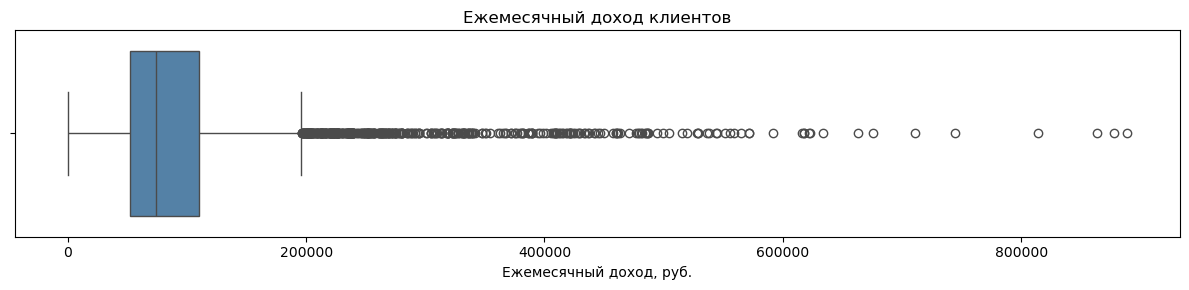

In [77]:
plt.figure(figsize=(12, 3))
sns.boxplot(x=clients["monthly_income"], color="steelblue")
plt.title("Ежемесячный доход клиентов")
plt.xlabel("Ежемесячный доход, руб.")
plt.tight_layout()
plt.show()

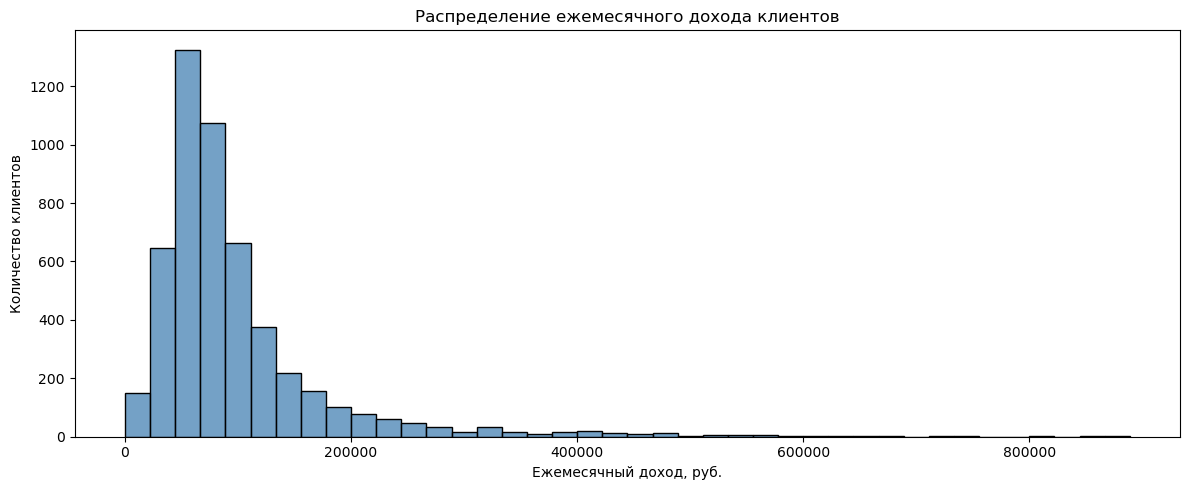

In [78]:
plt.figure(figsize=(12, 5))
sns.histplot(clients["monthly_income"].dropna(), bins=40, color="steelblue")
plt.title("Распределение ежемесячного дохода клиентов")
plt.xlabel("Ежемесячный доход, руб.")
plt.ylabel("Количество клиентов")
plt.tight_layout()
plt.show()

На обычной гистограмме маленькие значения почти не видны из-за большого диапазона доходов. Поэтому ниже тот же столбец показан с логарифмической шкалой по оси X.

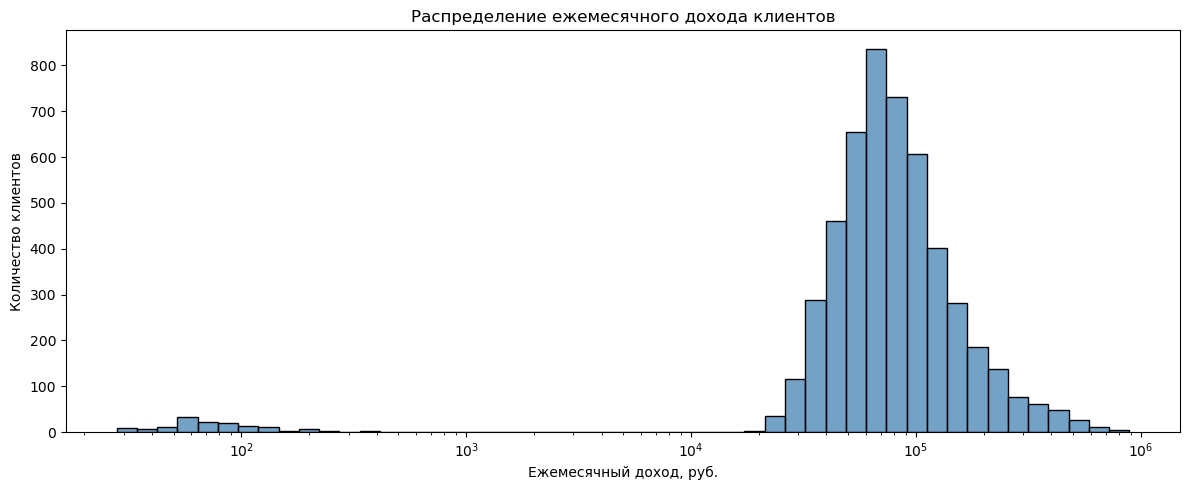

In [79]:
plt.figure(figsize=(12, 5))
sns.histplot(
    data=clients,
    x="monthly_income",
    bins=50,
    log_scale=True,
    color="steelblue",
)
plt.title("Распределение ежемесячного дохода клиентов")
plt.xlabel("Ежемесячный доход, руб.")
plt.ylabel("Количество клиентов")
plt.tight_layout()
plt.show()

На логарифмической гистограмме видна отдельная группа значений меньше 1 000 руб.. Возможно, эти доходы сохранились не в рублях, а в тысячах рублей: например, значение 75 на самом деле означает 75 000 руб.

Гипотеза проверена по сегментам. Для подозрительных значений доход условно умножен на 1 000, а полученная медиана сравнена с медианой остальных клиентов того же сегмента. Пока это только проверка - исходные данные в этой ячейке не изменяются.

In [80]:
low_income_mask = clients["monthly_income"].between(0, 1000, inclusive="neither")

low_income_stats = (
    clients.loc[low_income_mask]
    .groupby("segment")["monthly_income"]
    .agg(Клиентов="size", Минимум="min", Медиана="median", Максимум="max")
)

other_income_median = (
    clients.loc[clients["monthly_income"].notna() & ~low_income_mask]
    .groupby("segment")["monthly_income"]
    .median()
)

income_unit_check = low_income_stats.copy()
income_unit_check["Медиана после ×1000, руб."] = income_unit_check["Медиана"] * 1000
income_unit_check["Медиана остальных клиентов, руб."] = other_income_median
income_unit_check["Отклонение от остальных, %"] = (
    income_unit_check["Медиана после ×1000, руб."]
    / income_unit_check["Медиана остальных клиентов, руб."] - 1
) * 100

income_unit_check = income_unit_check.reindex(
    ["Массовый", "Зарплатный", "Премиальный", "Private"]
)

display(income_unit_check.round(1))

,Клиентов,Минимум,Медиана,Максимум,"Медиана после ×1000, руб.","Медиана остальных клиентов, руб.","Отклонение от остальных, %"
segment,,,,,,,
Массовый,79,27.9,60.9,135.3,60900.0,60550.0,0.6
Зарплатный,40,38.8,88.2,214.2,88250.0,78250.0,12.8
Премиальный,19,72.2,145.7,268.9,145700.0,149200.0,-2.3
Private,5,262.2,355.4,424.0,355400.0,343800.0,3.4


После условного умножения на 1000 медианы этой группы близки к медианам остальных клиентов соответствующих сегментов. Поэтому принято, что в этих строках доход ошибочно записан в тысячах рублей

In [81]:
income_scale_mask = clients["monthly_income"].between(0, 1000, inclusive="neither")
n_income_scaled = int(income_scale_mask.sum())

clients.loc[income_scale_mask, "monthly_income"] *= 1000

add_log(
    "monthly_income",
    "Часть доходов записана в тысячах рублей вместо рублей",
    "Строки с 0 < monthly_income < 1000",
    n_income_scaled,
    "27.9-424.0 (тыс. руб.)",
    "Значения умножены на 1000",
    "27 900-424 000 руб.",
    "После ×1000 медианы по сегментам близки к медианам остальных клиентов тех же сегментов",
)

assert not clients["monthly_income"].between(0, 1000, inclusive="neither").any()
print(f"Скорректировано значений monthly_income: {n_income_scaled}")

Скорректировано значений monthly_income: 143


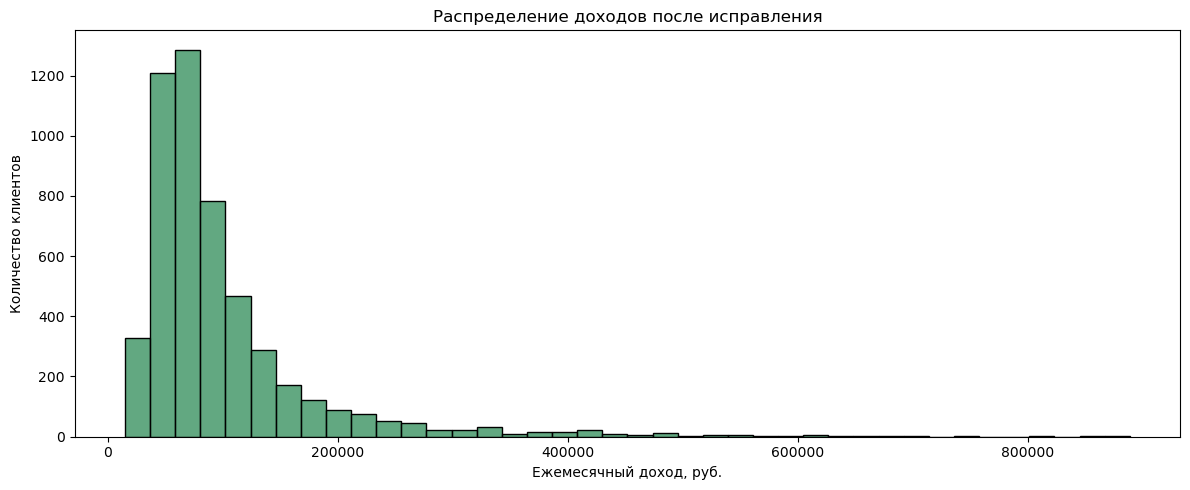

In [82]:
plt.figure(figsize=(12, 5))
sns.histplot(clients["monthly_income"].dropna(), bins=40, color="seagreen")
plt.title("Распределение доходов после исправления")
plt.xlabel("Ежемесячный доход, руб.")
plt.ylabel("Количество клиентов")
plt.tight_layout()
plt.show()

Высокие значения дохода были проверены по клиентским сегментам. Большинство значений выше верхней границы МКР относится к премиальному и Private-сегментам, поэтому они могут отражать реальные доходы клиентов. Оснований для удаления или ограничения этих значений нет.

In [83]:
income_q1 = clients["monthly_income"].quantile(0.25)
income_q3 = clients["monthly_income"].quantile(0.75)
income_upper = income_q3 + 1.5 * (income_q3 - income_q1)
high_income_mask = clients["monthly_income"] > income_upper

add_log(
    "monthly_income",
    "Высокие значения выше верхней границы МКР",
    f"Строки с monthly_income > {income_upper:.1f}",
    high_income_mask.sum(),
    f"{clients.loc[high_income_mask, 'monthly_income'].min():.0f}-{clients.loc[high_income_mask, 'monthly_income'].max():.0f} руб.",
    "Оставлено без изменения",
    "Исходные значения сохранены",
    "Большинство значений относится к премиальному и Private-сегментам и может отражать реальные доходы",
)

display(cleaning_log.tail(1))

,field,issue,scope,n_rows,value_before,action,value_after,rationale
14,monthly_income,Высокие значения выше верхней границы МКР,Строки с monthly_income > 196387.5,425,196500-888800 руб.,Оставлено без изменения,Исходные значения сохранены,Большинство значений относится к премиальному ...


**birth_date**

In [84]:
age = (
    pd.Timestamp("2025-06-30") - clients["birth_date"]
).dt.days / 365.2425

age_q1 = age.quantile(0.25)
age_median = age.median()
age_q3 = age.quantile(0.75)
age_iqr = age_q3 - age_q1

age_summary = pd.Series({
    "Количество клиентов": age.count(),
    "Минимальный возраст, лет": age.min(),
    "Первый квартиль Q1, лет": age_q1,
    "Медианный возраст, лет": age_median,
    "Третий квартиль Q3, лет": age_q3,
    "Максимальный возраст, лет": age.max(),
    "Межквартильный размах, лет": age_iqr,
})

display(age_summary.round(1).to_frame("Значение"))

,Значение
Количество клиентов,5690.0
"Минимальный возраст, лет",22.1
"Первый квартиль Q1, лет",43.3
"Медианный возраст, лет",51.9
"Третий квартиль Q3, лет",62.4
"Максимальный возраст, лет",88.9
"Межквартильный размах, лет",19.2


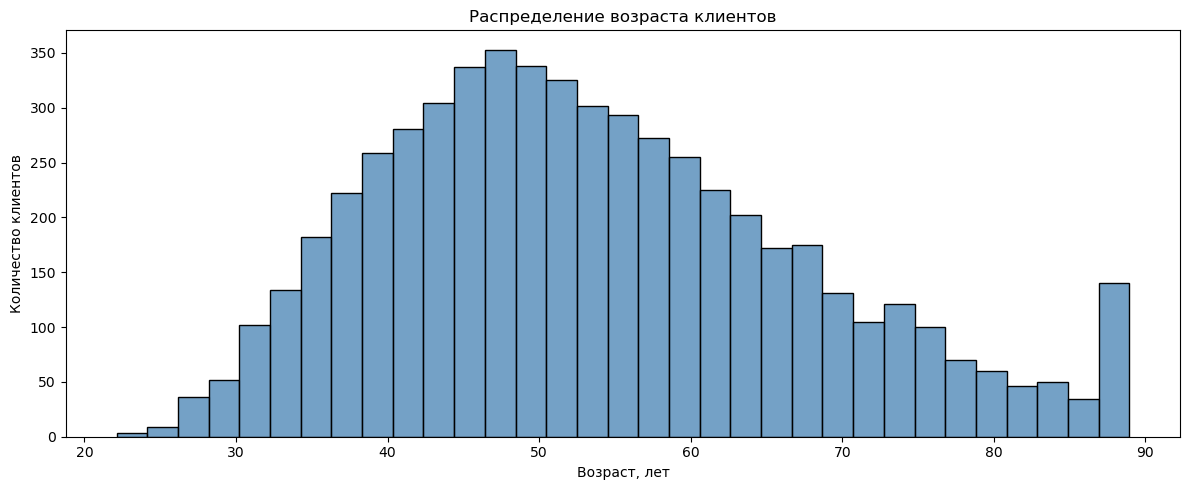

In [85]:
plt.figure(figsize=(12, 5))
sns.histplot(age.dropna(), binwidth=2, color="steelblue")
plt.title("Распределение возраста клиентов")
plt.xlabel("Возраст, лет")
plt.ylabel("Количество клиентов")
plt.tight_layout()
plt.show()

In [86]:
age_full_years = np.floor(age).astype(int)

upper_age_frequency = (
    age_full_years[age_full_years >= 75]
    .value_counts()
    .sort_index()
    .rename("Количество клиентов")
    .to_frame()
)

display(upper_age_frequency)

,Количество клиентов
birth_date,
75,45
76,47
77,36
78,34
79,30
80,27
81,25
82,21
83,24


В распределении возраста выявлена аномалия: 125 клиентов имеют полный возраст 88 лет, заметно больше, чем в соседних возрастах. Странность зафиксирована без дополнительной обработки.

In [87]:
age_88_mask = age_full_years.eq(88)

add_log(
    "birth_date",
    "Необычно высокая частота клиентов с возрастом 88 лет",
    "Клиенты с полным возрастом 88 лет на 30.06.2025",
    age_88_mask.sum(),
    f"{age_88_mask.sum()} клиентов одного возраста, заметно больше соседних возрастов",
    "Оставлено без изменения",
    "Исходные даты рождения сохранены",
    "Без дополнительного источника нельзя определить, какие даты рождения ошибочны",
)

display(cleaning_log.tail(1))

,field,issue,scope,n_rows,value_before,action,value_after,rationale
15,birth_date,Необычно высокая частота клиентов с возрастом ...,Клиенты с полным возрастом 88 лет на 30.06.2025,125,"125 клиентов одного возраста, заметно больше с...",Оставлено без изменения,Исходные даты рождения сохранены,Без дополнительного источника нельзя определит...


**txn_datetime**

 По условию данные должны охватывать период с 01.01.2024 по 30.06.2025. Границы txn_datetime проверены отдельно от решения о фильтрации: на этом шаге измерено количество операций вне заявленного окна.

In [88]:
period_start = pd.Timestamp("2024-01-01")
period_end_exclusive = pd.Timestamp("2025-07-01")

date_outlier_mask = (
    txn["txn_datetime"].lt(period_start)
    | txn["txn_datetime"].ge(period_end_exclusive)
)
date_outliers = txn.loc[date_outlier_mask].copy()

date_outlier_summary = pd.Series({
    "Операций до 01.01.2024": int(txn["txn_datetime"].lt(period_start).sum()),
    "Операций после 30.06.2025": int(txn["txn_datetime"].ge(period_end_exclusive).sum()),
    "Всего операций вне периода": int(date_outlier_mask.sum()),
    "Минимальная дата среди выбросов": date_outliers["txn_datetime"].min(),
    "Максимальная дата среди выбросов": date_outliers["txn_datetime"].max(),
}, name="Значение")
display(date_outlier_summary.to_frame())

,Значение
Операций до 01.01.2024,2
Операций после 30.06.2025,82
Всего операций вне периода,84
Минимальная дата среди выбросов,2023-12-03 16:37:58
Максимальная дата среди выбросов,2026-08-03 14:12:43


### 3.5. Фильтры, применяемые перед расчётом активности

 В txn_datetime оставлены операции только за заявленный период

 Для повторяющегося txn_id сохранена строка с более поздним txn_datetime: остальные поля совпадают, а все варианты каждого идентификатора относятся к одному календарному дню

 Из таблицы транзакций исключены операции без соответствующего client_id в таблице клиентов, поскольку их невозможно связать с признаками клиента и отнести к группе кампании.

 Оставлены только успешные операции: отклонённая операция не является состоявшейся активностью, а возврат является обратной операцией.
 
 Исключены 15 конфликтующих client_id, для которых различаются город или сегмент. Это лишь около 0,26% уникальных клиентов, а произвольный выбор строки исказил бы сегментацию.

In [89]:
n_before_date_filter = len(txn)
valid_period_mask = (
    txn["txn_datetime"].ge(period_start)
    & txn["txn_datetime"].lt(period_end_exclusive)
)
n_date_removed = int((~valid_period_mask).sum())
txn = txn.loc[valid_period_mask].copy()

add_log(
    "txn_datetime", "Операции находятся вне заявленного периода анализа",
    "txn_datetime < 2024-01-01 или txn_datetime >= 2025-07-01", n_date_removed,
    "2023-12-03 16:37:58 - 2026-08-03 14:12:43",
    "Операции исключены из аналитической таблицы",
    "2024-01-01 00:00:00 - 2025-06-30 23:59:59",
    "Фильтр приводит данные к периоду из TASK.md и исключает операции вне окон метрики",
)

In [90]:
n_before_txn_id = len(txn)
txn = (
    txn.sort_values("txn_datetime")
    .drop_duplicates("txn_id", keep="last")
    .copy()
)
n_txn_id_removed = n_before_txn_id - len(txn)

add_log(
    "txn_id, txn_datetime", "Повторяющиеся txn_id с различающимся временем",
    "txn_id встречается более одного раза после удаления полных дублей", n_txn_id_removed,
    "196 идентификаторов по две строки; различается только время внутри одного месяца",
    "Для каждого txn_id оставлена строка с максимальным txn_datetime",
    "Одна строка на txn_id",
    "Остальные поля совпадают, а варианты txn_id относятся к одному дню; дневная метрика не меняется",
)

In [91]:
known_client_mask = txn["client_id"].isin(clients["client_id"])
n_orphan_txn_removed = int((~known_client_mask).sum())
txn = txn.loc[known_client_mask].copy()

add_log(
    "transactions.client_id", "Для операции нет клиента в справочнике clients",
    "client_id отсутствует в clients", n_orphan_txn_removed,
    "Операции 325 неизвестных client_id",
    "Операции исключены из аналитической таблицы",
    "Остались операции, связанные с характеристиками клиента",
    "Без клиентской записи операцию нельзя сегментировать и включить в адресную кампанию",
)

In [92]:
non_success_counts = txn.loc[txn["status"].ne("успешно"), "status"].value_counts().to_dict()
success_mask = txn["status"].eq("успешно")
n_non_success_removed = int((~success_mask).sum())
txn = txn.loc[success_mask].copy()

add_log(
    "status", "Отклонённые операции и возвраты не отражают состоявшуюся покупательскую активность",
    "status != 'успешно'", n_non_success_removed,
    str(non_success_counts), "Операции исключены из основной метрики активности",
    "status = 'успешно'",
    "Метрика должна учитывать только состоявшиеся операции; возвраты можно анализировать отдельно",
)

In [93]:
ambiguous_client_ids = clients.loc[
    clients["client_id"].duplicated(keep=False), "client_id"
].unique()
ambiguous_txn_mask = txn["client_id"].isin(ambiguous_client_ids)
n_ambiguous_txn_removed = int(ambiguous_txn_mask.sum())
txn = txn.loc[~ambiguous_txn_mask].copy()
n_ambiguous_client_rows = int(clients["client_id"].isin(ambiguous_client_ids).sum())
clients = clients.loc[~clients["client_id"].isin(ambiguous_client_ids)].copy()

add_log(
    "clients.client_id, city, segment", "Для одного client_id конфликтуют город или сегмент",
    "15 повторяющихся client_id с различающимися city или segment", n_ambiguous_client_rows,
    "30 строк для 15 client_id", "Клиенты исключены из аналитической выборки",
    "Конфликтующие client_id отсутствуют в clients",
    "Нельзя обоснованно выбрать город или сегмент; 15 клиентов - около 0,26% справочника",
)
add_log(
    "transactions.client_id", "Операции относятся к клиентам с конфликтующими признаками",
    "client_id входит в список 15 неоднозначных клиентов", n_ambiguous_txn_removed,
    "Успешные операции неоднозначно сегментируемых клиентов",
    "Операции исключены из аналитической таблицы",
    "Остались операции клиентов с однозначными признаками",
    "Исключение предотвращает произвольное присвоение клиента городу или сегменту",
)

In [94]:
assert txn["txn_id"].is_unique
assert txn["client_id"].isin(clients["client_id"]).all()
assert txn["status"].eq("успешно").all()
assert not clients["client_id"].duplicated().any()

## 4. Журнал изменений

Одна строка - одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [95]:
# cleaning_log создан в разделе 0 и заполнялся сразу после каждого преобразования

In [96]:
cleaning_log

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,"birth_date, registration_date, card_open_date",Даты представлены текстом,Все строки таблицы клиентов,5730,Текстовые даты,Преобразовано в datetime,datetime64[ns],Для сравнения дат и расчёта возраста и стажа к...
1,app_last_login,Последний вход указан с точностью до месяца,Строки с заполненным app_last_login,3508,Год и месяц,Преобразовано в datetime,Дата с первым числом месяца,Добавленный день не является фактическим днём ...
2,txn_datetime,Разные форматы: дата со временем и без времени,Строки с заполненным txn_datetime,624400,574754 дат со временем и 49646 дат без времени,Оба обнаруженных формата разобраны отдельно и ...,datetime64[ns]; даты без времени получили 00:0...,Явные форматы исключают неоднозначный автомати...
3,"amount, status",Отрицательные суммы требуют смысловой проверки,Все строки с amount < 0,7432,7432 отрицательные суммы; во всех строках stat...,Значения оставлены без исправления знака,Отрицательная сумма сохранена как сумма возврата,Совпадение масок amount < 0 и status = 'возвра...
4,Все поля,Полные дубли строк клиентов,Таблица клиентов: полностью одинаковые строки,40,Одинаковые строки встречаются несколько раз,Удалены полные дубли,Сохранён один экземпляр каждой строки,Исключить повторный учёт клиентов и размножени...
5,Все поля,Полные дубли транзакций,Таблица транзакций: полностью одинаковые строки,1304,Одинаковые строки встречаются несколько раз,Удалены полные дубли,Сохранён один экземпляр каждой строки,Исключить завышение количества операций и сумм...
6,city,Разные написания одинаковых городов,Строки с названиями из словаря cities,1598,Н. Новгород; МОСКВА; москва; г. Москва; г. Но...,Названия приведены к единому виду,Екатеринбург; Казань; Москва; Нижний Новгород;...,Объединить записи одного города без изменения ...
7,category,Разные написания одинаковых категорий,Строки с названиями из словаря categories,61301,кафе и рестораны; Кафе/рестораны; Связь и инте...,Названия приведены к единому виду,Кафе и рестораны; Связь и Интернет,Чтобы расходы одной категории не разделялись м...
8,"category, mcc_code",Одному MCC-коду соответствуют несколько категорий,"Строки, где category не совпадает с категорией...",1666,category и mcc_code указывают на разные категории,Оставлено без изменения,Исходные category и mcc_code сохранены,Нельзя определить ошибочное поле; остальные да...
9,monthly_income,"Предполагаемый скрытый пропуск, обозначенный к...",Строки с monthly_income = -999,60,-999,Заменено на стандартный пропуск,NaN,Повторяющееся служебное значение трактуется к...


## 5. Разведочный анализ

В этом разделе показано, как распределены признаки клиентов и транзакций, как менялась активность по месяцам и в каких группах падение заметнее всего.

### 5.1. Распределения количественных признаков

Для возраста, длительности обслуживания, возраста карты и дохода рассчитаны медиана и межквартильный размах. Эти показатели подходят для распределений с выбросами лучше, чем среднее значение.

In [97]:
snapshot_date = pd.Timestamp("2025-06-30")
client_quantitative = clients.copy()
client_quantitative["age_years"] = (snapshot_date - client_quantitative["birth_date"]).dt.days / 365.2425
client_quantitative["relationship_years"] = (snapshot_date - client_quantitative["registration_date"]).dt.days / 365.2425
client_quantitative["current_card_age_years"] = (snapshot_date - client_quantitative["card_open_date"]).dt.days / 365.2425

quantitative_fields = {
    "Возраст клиента, лет": "age_years",
    "Длительность обслуживания в банке, лет": "relationship_years",
    "Возраст текущей карты, лет": "current_card_age_years",
    "Ежемесячный доход, руб.": "monthly_income",
}
quantitative_summary = pd.DataFrame({
    label: {
        "Заполнено": client_quantitative[field].notna().sum(),
        "Пропуски": client_quantitative[field].isna().sum(),
        "Минимум": client_quantitative[field].min(),
        "Q1": client_quantitative[field].quantile(0.25),
        "Медиана": client_quantitative[field].median(),
        "Q3": client_quantitative[field].quantile(0.75),
        "P99": client_quantitative[field].quantile(0.99),
        "Максимум": client_quantitative[field].max(),
    }
    for label, field in quantitative_fields.items()
}).T
display(quantitative_summary.round(2))

,Заполнено,Пропуски,Минимум,Q1,Медиана,Q3,P99,Максимум
"Возраст клиента, лет",5660.0,0.0,22.12,43.25,51.87,62.41,88.55,88.94
"Длительность обслуживания в банке, лет",5660.0,0.0,0.27,5.38,7.85,10.11,14.39,15.49
"Возраст текущей карты, лет",5660.0,0.0,0.13,2.49,4.84,7.09,9.41,9.49
"Ежемесячный доход, руб.",5080.0,580.0,15200.00,54675.00,75500.00,111225.00,447251.00,888800.00


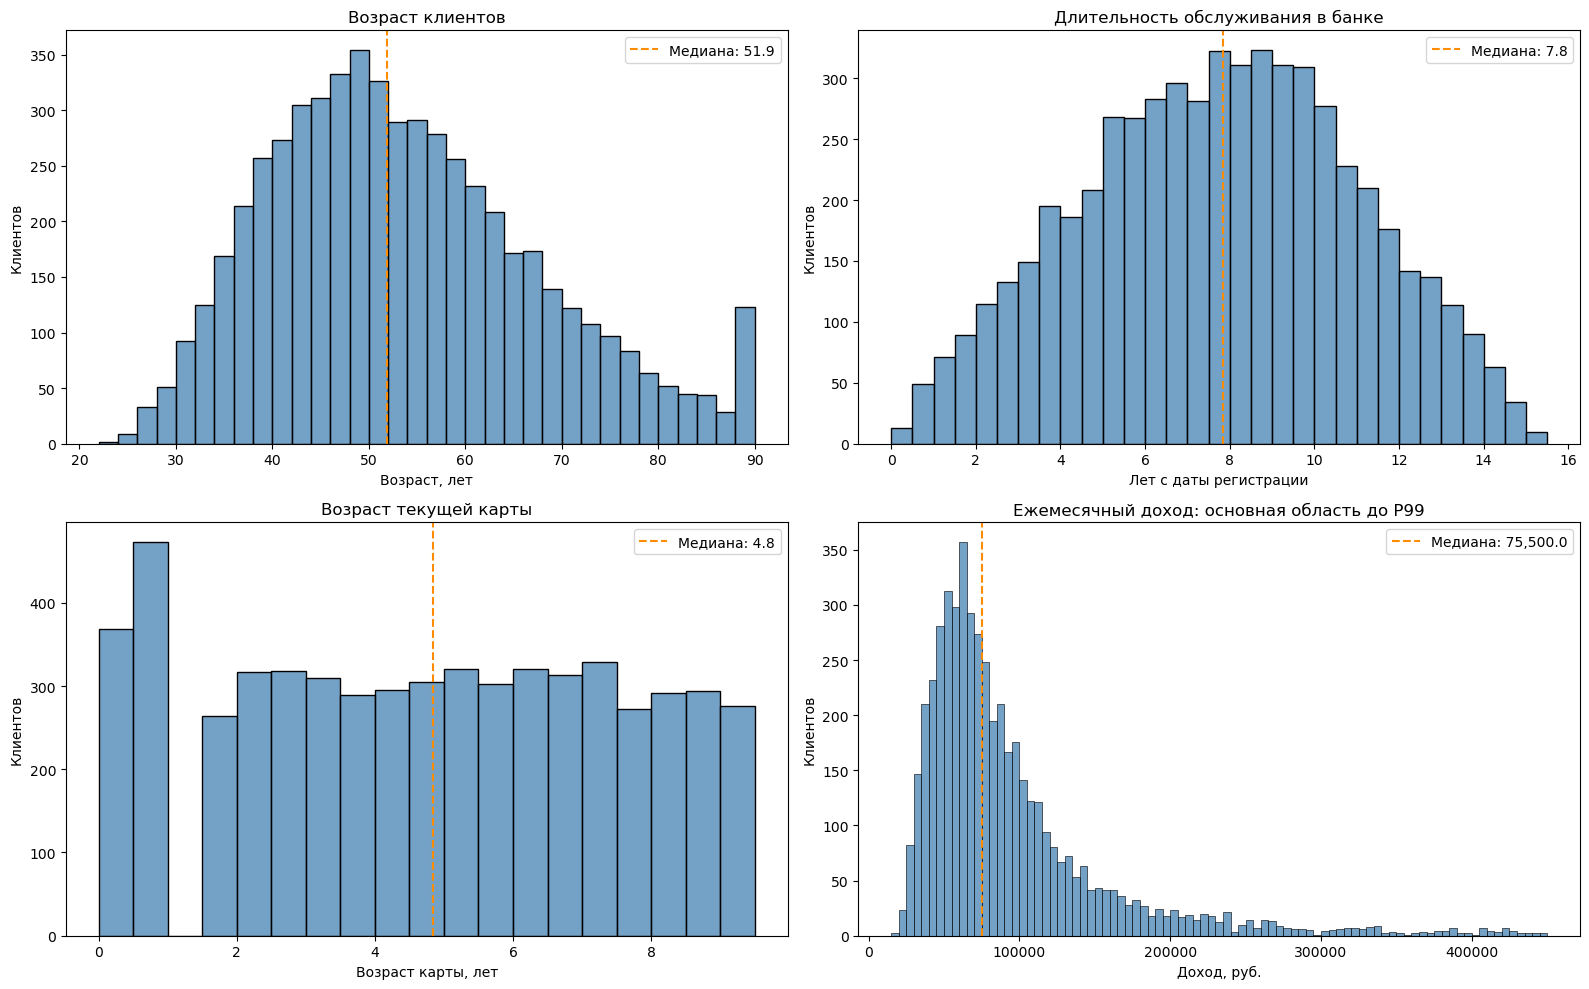

In [98]:
def fixed_step_bins(series, step, upper=None):
    values = series.dropna()
    lower_edge = np.floor(values.min() / step) * step
    upper_value = values.max() if upper is None else upper
    upper_edge = np.ceil(upper_value / step) * step
    return np.arange(lower_edge, upper_edge + step, step)

income_p99 = client_quantitative["monthly_income"].quantile(0.99)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
plot_specs = [
    ("age_years", 2, None, "Возраст клиентов", "Возраст, лет"),
    ("relationship_years", 0.5, None, "Длительность обслуживания в банке", "Лет с даты регистрации"),
    ("current_card_age_years", 0.5, None, "Возраст текущей карты", "Возраст карты, лет"),
    ("monthly_income", 5000, income_p99, "Ежемесячный доход: основная область до P99", "Доход, руб."),
]
for ax, (field, step, upper, title, xlabel) in zip(axes.flat, plot_specs):
    values = client_quantitative[field].dropna()
    displayed = values if upper is None else values[values <= upper]
    sns.histplot(displayed, bins=fixed_step_bins(values, step, upper), ax=ax, color="steelblue")
    ax.axvline(values.median(), color="darkorange", linestyle="--", label=f"Медиана: {values.median():,.1f}")
    ax.set(title=title, xlabel=xlabel, ylabel="Клиентов")
    ax.legend()
plt.tight_layout()
plt.show()

Суммы транзакций рассмотрены отдельно для RUB, USD и EUR.

,observations,minimum,median,maximum,p95,p99,above_p99
currency,,,,,,,
RUB,571942,3.18,1098.84,227522.49,6400.86,12525.39,5720
USD,1168,0.12,12.97,312.28,70.21,123.34,12
EUR,1092,0.09,11.98,384.17,74.96,147.49,11


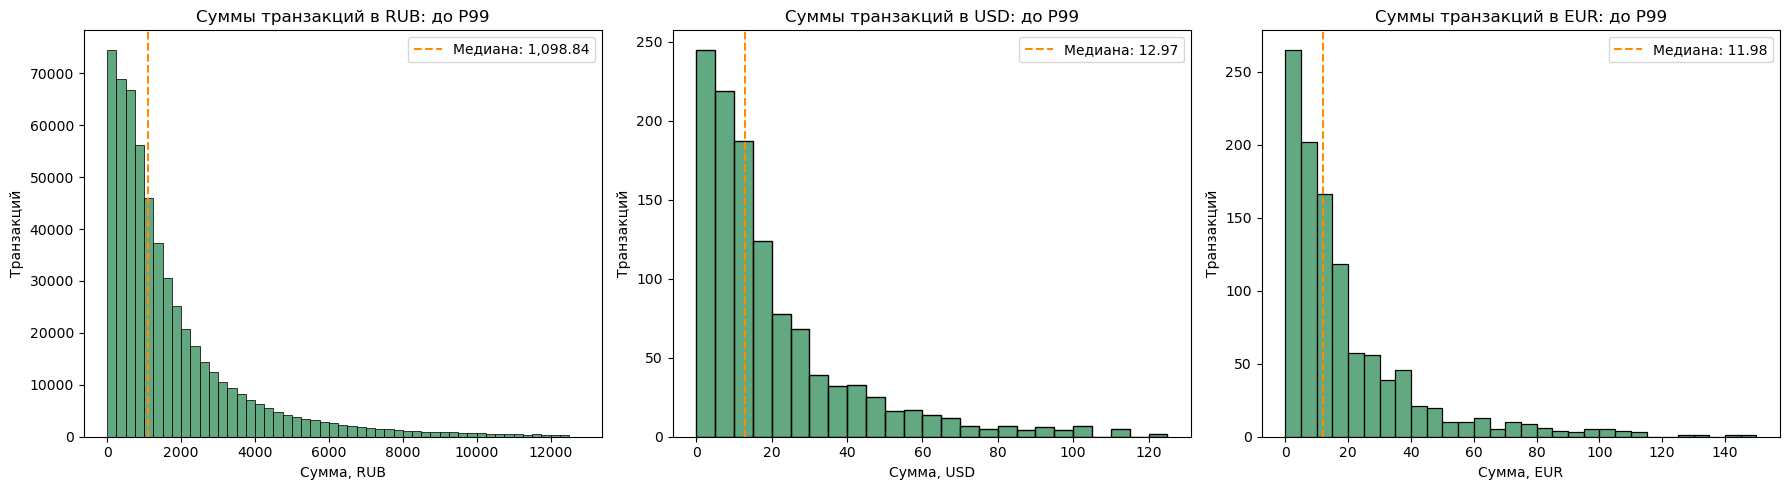

In [99]:
currency_order = ["RUB", "USD", "EUR"]
amount_steps = {"RUB": 250, "USD": 5, "EUR": 5}
amount_summary = txn.groupby("currency")["amount"].agg(
    observations="size", minimum="min", median="median", maximum="max"
).reindex(currency_order)
amount_summary["p95"] = txn.groupby("currency")["amount"].quantile(0.95).reindex(currency_order)
amount_summary["p99"] = txn.groupby("currency")["amount"].quantile(0.99).reindex(currency_order)
amount_summary["above_p99"] = [
    txn.loc[txn["currency"].eq(currency), "amount"].gt(amount_summary.loc[currency, "p99"]).sum()
    for currency in currency_order
]
display(amount_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, currency in zip(axes, currency_order):
    values = txn.loc[txn["currency"].eq(currency), "amount"]
    upper = amount_summary.loc[currency, "p99"]
    step = amount_steps[currency]
    sns.histplot(
        values[values <= upper],
        bins=np.arange(0, np.ceil(upper / step) * step + step, step),
        ax=ax, color="seagreen",
    )
    ax.axvline(values.median(), color="darkorange", linestyle="--", label=f"Медиана: {values.median():,.2f}")
    ax.set(title=f"Суммы транзакций в {currency}: до P99", xlabel=f"Сумма, {currency}", ylabel="Транзакций")
    ax.legend()
plt.tight_layout()
plt.show()

In [100]:
txn.loc[txn["amount"].idxmax(), ["amount", "currency", "category"]]

amount           227522.49
currency               RUB
category    Одежда и обувь
Name: 471136, dtype: object

### 5.2. Частотные характеристики категориальных признаков

Для категориальных признаков таблицы клиентов показаны количество и доля от всех 5 660 клиентов. 

In [101]:
client_columns = {
    "Сегмент": "segment",
    "Уровень лояльности": "loyalty_tier",
    "Тип карты": "card_type",
    "Город": "city",
    "Мобильное приложение": "has_mobile_app",
    "Согласие на коммуникацию": "marketing_opt_in",
    "Источник дохода": "income_source",
    "Оценка обслуживания": "satisfaction_score",
}

client_share_column = f"Доля от {len(clients):,} клиентов, %".replace(",", " ")

client_frequency_parts = []
for title, column in client_columns.items():
    counts = clients[column].astype("string").fillna("Нет данных").value_counts()
    table = counts.rename("Количество").to_frame()
    table[client_share_column] = table["Количество"] / len(clients) * 100
    table.insert(0, "Признак", title)
    table.index.name = "Значение"
    client_frequency_parts.append(table.reset_index())

client_frequency_table = pd.concat(client_frequency_parts, ignore_index=True)
display(client_frequency_table.round(2))

,Значение,Признак,Количество,Доля от 5 660 клиентов %
0,Массовый,Сегмент,2882,50.92
1,Зарплатный,Сегмент,1600,28.27
2,Премиальный,Сегмент,948,16.75
3,Private,Сегмент,230,4.06
4,Базовый,Уровень лояльности,2801,49.49
5,Серебро,Уровень лояльности,1601,28.29
6,Золото,Уровень лояльности,955,16.87
7,Платина,Уровень лояльности,303,5.35
8,Дебетовая,Тип карты,3930,69.43
9,Кредитная,Тип карты,1247,22.03


Для каналов, категорий и валют знаменателем доли является 574 202 очищенные успешные транзакции.

In [102]:
transaction_columns = {
    "Канал": "channel",
    "Категория": "category",
    "Валюта": "currency",
}

transaction_share_column = f"Доля от {len(txn):,} транзакций, %".replace(",", " ")

transaction_frequency_parts = []
for title, column in transaction_columns.items():
    counts = txn[column].astype("string").fillna("Нет данных").value_counts()
    table = counts.rename("Количество").to_frame()
    table[transaction_share_column] = table["Количество"] / len(txn) * 100
    table["Клиентов"] = txn.groupby(column)["client_id"].nunique().reindex(counts.index).values
    table.insert(0, "Признак", title)
    table.index.name = "Значение"
    transaction_frequency_parts.append(table.reset_index())

transaction_frequency_table = pd.concat(transaction_frequency_parts, ignore_index=True)
display(transaction_frequency_table.round(2))

,Значение,Признак,Количество,Доля от 574 202 транзакций %,Клиентов
0,Карта,Канал,299136,52.1,5579
1,СБП,Канал,96253,16.76,5288
2,Токен,Канал,93321,16.25,5127
3,Онлайн-банк,Канал,85492,14.89,5292
4,Продукты,Категория,151155,26.32,5549
5,Кафе и рестораны,Категория,74710,13.01,5400
6,Транспорт,Категория,59903,10.43,5351
7,Одежда и обувь,Категория,58886,10.26,5332
8,АЗС,Категория,53050,9.24,5284
9,Развлечения и досуг,Категория,50158,8.74,5193


Ниже показано распределение клиентов по сегментам и наличию приложения, а транзакций - по каналам оплаты и категориям покупок.

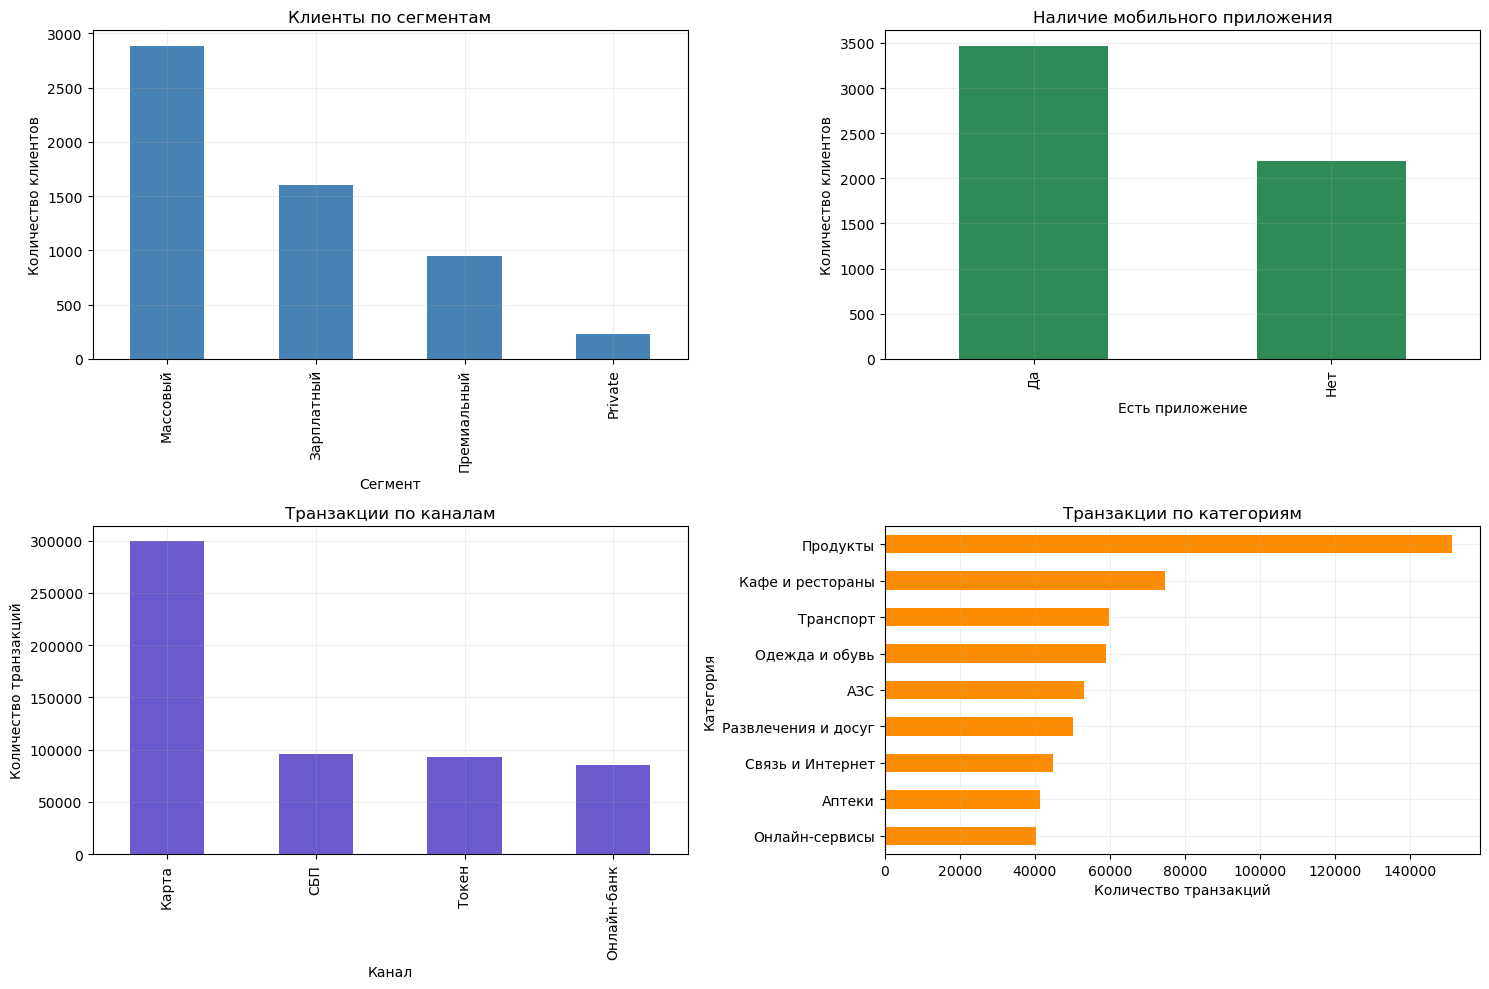

In [103]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

clients["segment"].value_counts().plot.bar(ax=axes[0, 0], color="steelblue")
axes[0, 0].set(title="Клиенты по сегментам", xlabel="Сегмент", ylabel="Количество клиентов")

clients["has_mobile_app"].value_counts().plot.bar(ax=axes[0, 1], color="seagreen")
axes[0, 1].set(title="Наличие мобильного приложения", xlabel="Есть приложение", ylabel="Количество клиентов")

txn["channel"].value_counts().plot.bar(ax=axes[1, 0], color="slateblue")
axes[1, 0].set(title="Транзакции по каналам", xlabel="Канал", ylabel="Количество транзакций")

txn["category"].value_counts().sort_values().plot.barh(ax=axes[1, 1], color="darkorange")
axes[1, 1].set(title="Транзакции по категориям", xlabel="Количество транзакций", ylabel="Категория")

for ax in axes.flat:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 5.3. Динамика по месяцам

По каждому месяцу рассчитаны число транзакций, число и доля активных клиентов, а также транзакции на одного активного клиента. Активным считается клиент, совершивший хотя бы одну успешную транзакцию в конкретном календарном месяце.

In [104]:
analysis_months = pd.date_range("2024-01-01", "2025-06-01", freq="MS")

txn_monthly = txn.assign(
    month=txn["txn_datetime"].dt.to_period("M").dt.to_timestamp(),
    txn_date=txn["txn_datetime"].dt.date,
)

monthly_activity = (
    txn_monthly.groupby("month")
    .agg(
        transactions=("txn_id", "size"),
        active_clients=("client_id", "nunique"),
    )
    .reindex(analysis_months, fill_value=0)
)

active_client_days = (
    txn_monthly.drop_duplicates(["month", "txn_date", "client_id"])
    .groupby("month")
    .size()
)

monthly_activity["active_client_days"] = active_client_days.reindex(
    analysis_months, fill_value=0
)

transaction_days = txn_monthly.groupby("month")["txn_date"].nunique()
monthly_activity["transaction_days"] = transaction_days.reindex(
    analysis_months, fill_value=0
)
monthly_activity.index.name = "Месяц"
monthly_activity["calendar_days"] = monthly_activity.index.days_in_month
monthly_activity["transactions_per_day"] = (
    monthly_activity["transactions"] / monthly_activity["calendar_days"]
)
monthly_activity["registered_clients"] = [
    clients["registration_date"].le(month + pd.offsets.MonthEnd(0)).sum()
    for month in monthly_activity.index
]
monthly_activity["active_clients_share_of_registered_pct"] = (
    monthly_activity["active_clients"] / monthly_activity["registered_clients"] * 100
)
monthly_activity["transactions_per_active_client"] = (
    monthly_activity["transactions"] / monthly_activity["active_clients"]
)

display(monthly_activity.round(2))

,transactions,active_clients,active_client_days,transaction_days,calendar_days,transactions_per_day,registered_clients,active_clients_share_of_registered_pct,transactions_per_active_client
Месяц,,,,,,,,,
2024-01-01,23983,4646,21405,31,31,773.65,5545,83.79,5.16
2024-02-01,29985,4709,25902,29,29,1033.97,5553,84.80,6.37
2024-03-01,34509,4741,29717,31,31,1113.19,5561,85.25,7.28
2024-04-01,33761,4745,28695,30,30,1125.37,5580,85.04,7.12
2024-05-01,31215,4725,27176,31,31,1006.94,5594,84.47,6.61
2024-06-01,33411,4735,28615,30,30,1113.70,5600,84.55,7.06
2024-07-01,34368,4780,29300,31,31,1108.65,5611,85.19,7.19
2024-08-01,35706,4843,30589,31,31,1151.81,5616,86.24,7.37
2024-09-01,33742,4871,28922,30,30,1124.73,5625,86.60,6.93


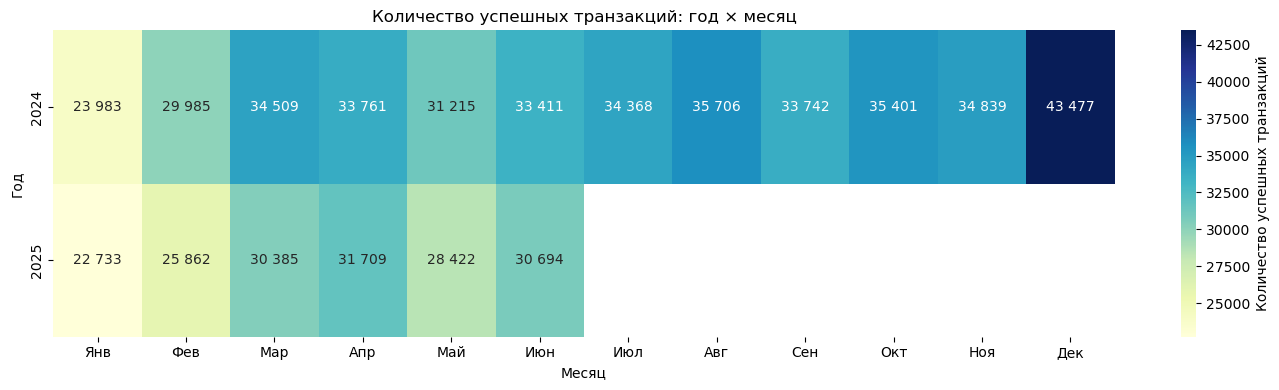

In [105]:
monthly_transaction_counts = (
    txn.assign(year=txn["txn_datetime"].dt.year, month=txn["txn_datetime"].dt.month)
    .groupby(["year", "month"]).size().unstack("month")
    .reindex(columns=range(1, 13))
)
month_labels = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
monthly_transaction_counts.columns = month_labels
heatmap_labels = monthly_transaction_counts.applymap(
    lambda value: f"{int(value):,}".replace(",", " " ) if pd.notna(value) else ""
)
plt.figure(figsize=(14, 4))
sns.heatmap(
    monthly_transaction_counts, annot=heatmap_labels, fmt="", cmap="YlGnBu",
    mask=monthly_transaction_counts.isna(),
    cbar_kws={"label": "Количество успешных транзакций"},
)
plt.title("Количество успешных транзакций: год × месяц")
plt.xlabel("Месяц")
plt.ylabel("Год")
plt.tight_layout()
plt.show()

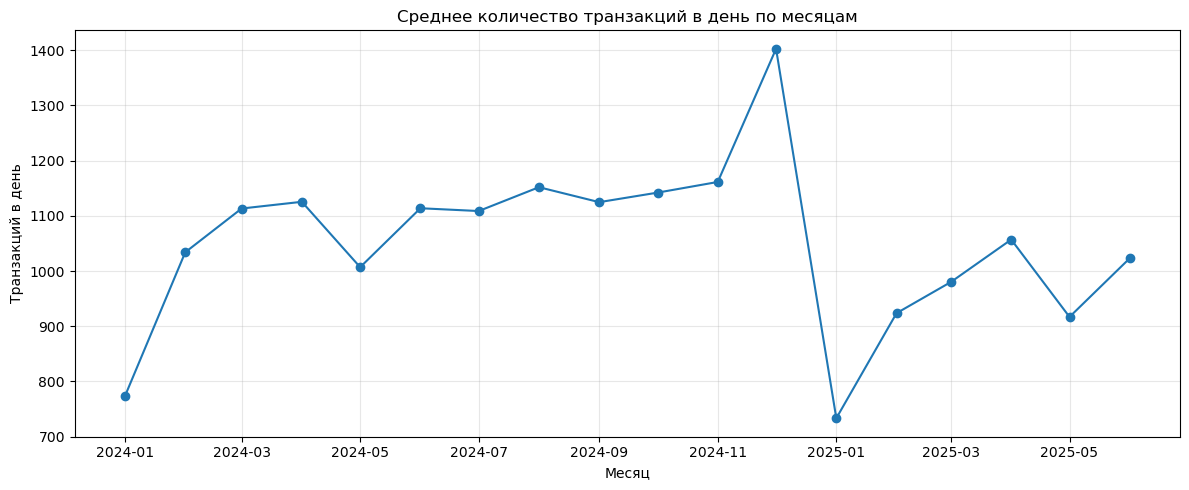

In [106]:
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_activity.index,
    monthly_activity["transactions_per_day"],
    marker="o",
)
plt.title("Среднее количество транзакций в день по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Транзакций в день")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Январь-июнь 2025 года сравнивается с теми же месяцами 2024 года. Так сезонность не смешивается с изменением активности.

In [107]:
month_names = ["Январь", "Февраль", "Март", "Апрель", "Май", "Июнь"]
h1_2024 = monthly_activity.loc["2024-01-01":"2024-06-01"].copy()
h1_2025 = monthly_activity.loc["2025-01-01":"2025-06-01"].copy()
yoy_comparison = pd.DataFrame(index=month_names)
for metric, label in {
    "transactions_per_day": "Транзакций в день",
    "active_clients_share_of_registered_pct": "Доля активных от зарегистрированных клиентов, %",
    "transactions_per_active_client": "Транзакций на активного клиента",
}.items():
    values_2024 = h1_2024[metric].to_numpy()
    values_2025 = h1_2025[metric].to_numpy()
    yoy_comparison[f"{label}: 2024"] = values_2024
    yoy_comparison[f"{label}: 2025"] = values_2025
    yoy_comparison[f"{label}: изменение, %"] = (values_2025 / values_2024 - 1) * 100
display(yoy_comparison.round(2))

,Транзакций в день: 2024,Транзакций в день: 2025,"Транзакций в день: изменение, %","Доля активных от зарегистрированных клиентов, %: 2024","Доля активных от зарегистрированных клиентов, %: 2025","Доля активных от зарегистрированных клиентов, %: изменение, %",Транзакций на активного клиента: 2024,Транзакций на активного клиента: 2025,"Транзакций на активного клиента: изменение, %"
Январь,773.65,733.32,-5.21,83.79,85.70,2.28,5.16,4.69,-9.07
Февраль,1033.97,923.64,-10.67,84.80,87.51,3.19,6.37,5.22,-17.98
Март,1113.19,980.16,-11.95,85.25,89.59,5.09,7.28,5.99,-17.68
Апрель,1125.37,1056.97,-6.08,85.04,91.31,7.38,7.12,6.14,-13.77
Май,1006.94,916.84,-8.95,84.47,88.36,4.61,6.61,5.68,-13.97
Июнь,1113.70,1023.13,-8.13,84.55,87.83,3.87,7.06,6.17,-12.49


Итоги двух полугодий сводим в одну таблицу, чтобы увидеть общее изменение показателей.

In [108]:
def summarize_period(frame):
    return pd.Series({
        "Транзакций всего": frame["transactions"].sum(),
        "Среднее транзакций в день": frame["transactions"].sum() / frame["calendar_days"].sum(),
        "Среднее число активных клиентов за месяц": frame["active_clients"].mean(),
        "Средняя доля активных от зарегистрированных клиентов, %": frame["active_clients_share_of_registered_pct"].mean(),
        "Среднее число транзакций на активного клиента за месяц": frame["transactions"].sum() / frame["active_clients"].sum()
    })

h1_summary = pd.DataFrame({
    "H1 2024": summarize_period(h1_2024),
    "H1 2025": summarize_period(h1_2025),
})
h1_summary["Изменение, %"] = (h1_summary["H1 2025"] / h1_summary["H1 2024"] - 1) * 100
display(h1_summary.round(2))

,H1 2024,H1 2025,"Изменение, %"
Транзакций всего,186864.00,169805.00,-9.13
Среднее транзакций в день,1026.73,938.15,-8.63
Среднее число активных клиентов за месяц,4716.83,5001.00,6.02
"Средняя доля активных от зарегистрированных клиентов, %",84.65,88.38,4.41
Среднее число транзакций на активного клиента за месяц,6.60,5.66,-14.29


В январе-июне 2025 года было 169 805 успешных транзакций. Это на 9,1% меньше, чем в январе-июне 2024 года.Транзакций в день стало меньше на 8,6%. Снижение видно во всех шести сопоставимых месяцах.
Среднее число активных клиентов выросло на 6,0%, а их доля среди зарегистрированных на конец каждого месяца увеличилась с 84,65% до 88,38%.
При этом транзакций на активного клиента стало меньше: 5,66 вместо 6,60 в месяц (−14,3%). Значит, клиентов стало не меньше,а каждый активный клиент в среднем совершает меньше операций.

### 5.4. Разрезы и связи между признаками

Ниже рассмотрены разрезы по признакам клиентов и операций. Для каждой группы рассчитано среднее число успешных транзакций на одного клиента в месяц. Сравниваются одинаковые периоды: январь-июнь 2024 года и январь-июнь 2025 года. В анализ входят 5 527 клиентов, зарегистрированных до 01.01.2024.

In [109]:
comparison_clients = clients.loc[
    clients["registration_date"] < "2024-01-01"
].copy()

comparison_txn = txn.loc[
    txn["client_id"].isin(comparison_clients["client_id"])
].copy()

h1_2024_txn = comparison_txn.loc[
    comparison_txn["txn_datetime"].between("2024-01-01", "2024-07-01", inclusive="left")
].copy()
h1_2025_txn = comparison_txn.loc[
    comparison_txn["txn_datetime"].between("2025-01-01", "2025-07-01", inclusive="left")
].copy()

h1_2024_txn["txn_date"] = h1_2024_txn["txn_datetime"].dt.date
h1_2025_txn["txn_date"] = h1_2025_txn["txn_datetime"].dt.date

h1_2024_client = h1_2024_txn.groupby("client_id").agg(
    h1_2024_transactions=("txn_id", "size"),
    h1_2024_active_days=("txn_date", "nunique"),
)
h1_2025_client = h1_2025_txn.groupby("client_id").agg(
    h1_2025_transactions=("txn_id", "size"),
    h1_2025_active_days=("txn_date", "nunique"),
)

client_change = comparison_clients.merge(
    h1_2024_client, on="client_id", how="left"
).merge(
    h1_2025_client, on="client_id", how="left"
)

metric_columns = [
    "h1_2024_transactions", "h1_2024_active_days",
    "h1_2025_transactions", "h1_2025_active_days",
]
client_change[metric_columns] = client_change[metric_columns].fillna(0)
client_change["h1_2024_monthly_transactions"] = client_change["h1_2024_transactions"] / 6
client_change["h1_2025_monthly_transactions"] = client_change["h1_2025_transactions"] / 6
client_change["transaction_change"] = (
    client_change["h1_2025_transactions"] - client_change["h1_2024_transactions"]
)
client_change["declined"] = client_change["transaction_change"] < 0
client_change["stopped"] = (
    (client_change["h1_2024_transactions"] > 0)
    & (client_change["h1_2025_transactions"] == 0)
)

#### Сегмент и наличие приложения

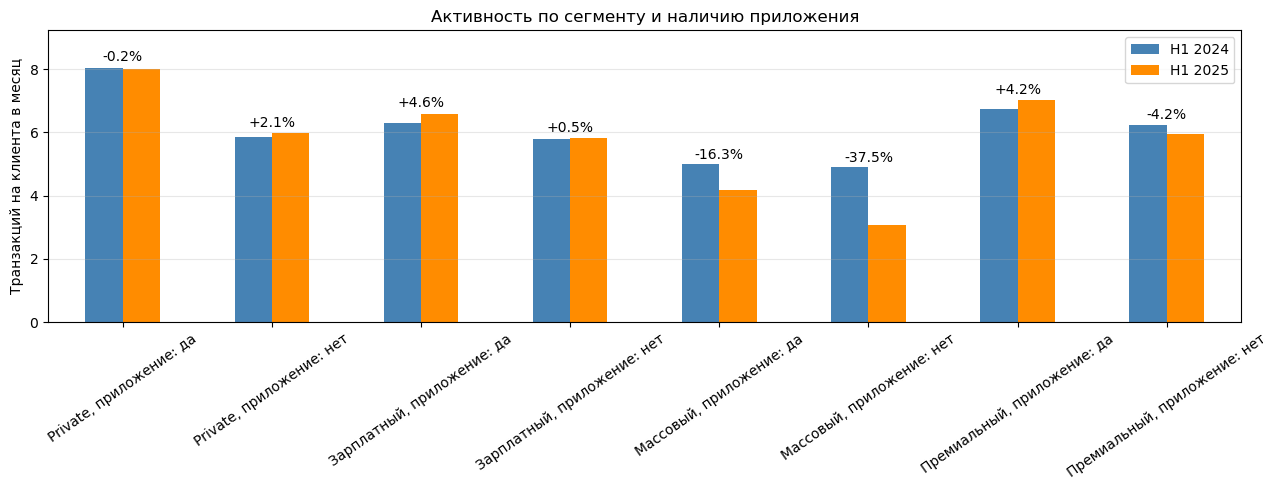

In [110]:
segment_app = client_change.groupby(
    ["segment", "has_mobile_app"]
)[["h1_2024_monthly_transactions", "h1_2025_monthly_transactions"]].mean()

segment_app.index = [
    f"{segment}, приложение: {'да' if app == 'Да' else 'нет'}"
    for segment, app in segment_app.index
]
segment_app.columns = ["H1 2024", "H1 2025"]

ax = segment_app.plot.bar(figsize=(13, 5), color=["steelblue", "darkorange"])

change_pct = (segment_app["H1 2025"] / segment_app["H1 2024"] - 1) * 100
for position, change in enumerate(change_pct):
    height = segment_app.iloc[position].max()
    ax.text(position, height * 1.03, f"{change:+.1f}%", ha="center")

ax.set_title("Активность по сегменту и наличию приложения")
ax.set_xlabel("")
ax.set_ylabel("Транзакций на клиента в месяц")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

На первом графике одновременно показаны сегмент клиента и наличие мобильного приложения.

#### Сегменты

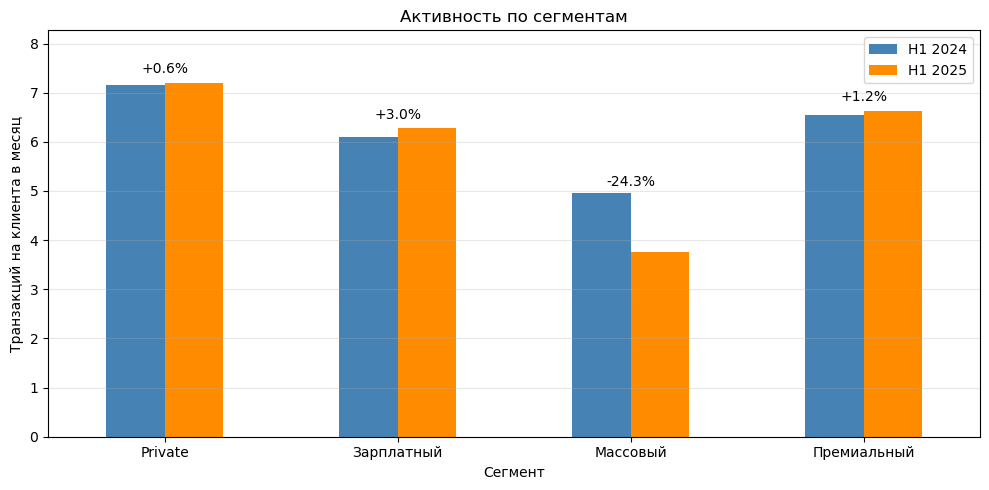

In [111]:
segment_activity = client_change.groupby("segment")[[
    "h1_2024_monthly_transactions",
    "h1_2025_monthly_transactions",
]].mean()
segment_activity.columns = ["H1 2024", "H1 2025"]

ax = segment_activity.plot.bar(figsize=(10, 5), color=["steelblue", "darkorange"])

change_pct = (segment_activity["H1 2025"] / segment_activity["H1 2024"] - 1) * 100
for position, change in enumerate(change_pct):
    height = segment_activity.iloc[position].max()
    ax.text(position, height * 1.03, f"{change:+.1f}%", ha="center")

ax.set_title("Активность по сегментам")
ax.set_xlabel("Сегмент")
ax.set_ylabel("Транзакций на клиента в месяц")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

#### Категории покупок

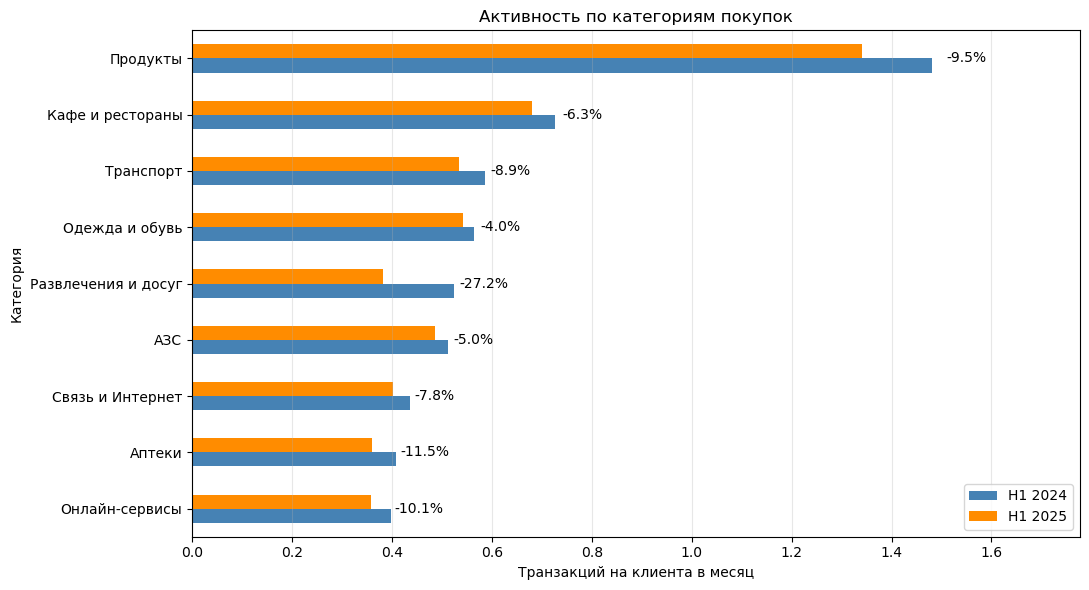

In [112]:
category_activity = pd.DataFrame({
    "H1 2024": h1_2024_txn["category"].value_counts() / len(comparison_clients) / 6,
    "H1 2025": h1_2025_txn["category"].value_counts() / len(comparison_clients) / 6,
}).fillna(0).sort_values("H1 2024")

ax = category_activity.plot.barh(
    figsize=(11, 6), color=["steelblue", "darkorange"]
)

change_pct = (category_activity["H1 2025"] / category_activity["H1 2024"] - 1) * 100
for position, change in enumerate(change_pct):
    width = category_activity.iloc[position].max()
    ax.text(width * 1.02, position, f"{change:+.1f}%", va="center")

ax.set_title("Активность по категориям покупок")
ax.set_xlabel("Транзакций на клиента в месяц")
ax.set_ylabel("Категория")
ax.grid(axis="x", alpha=0.3)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()

#### Каналы оплаты

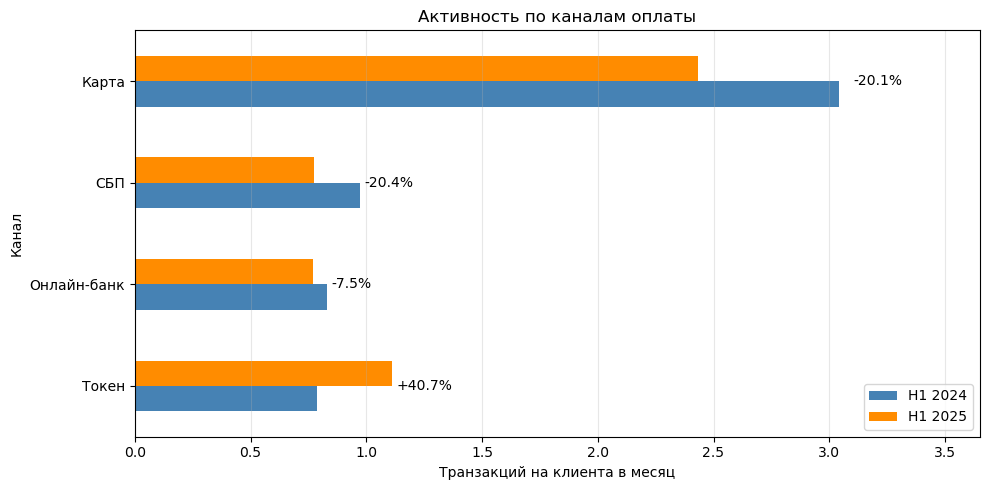

In [113]:
channel_activity = pd.DataFrame({
    "H1 2024": h1_2024_txn["channel"].value_counts() / len(comparison_clients) / 6,
    "H1 2025": h1_2025_txn["channel"].value_counts() / len(comparison_clients) / 6,
}).fillna(0).sort_values("H1 2024")

ax = channel_activity.plot.barh(
    figsize=(10, 5), color=["steelblue", "darkorange"]
)

change_pct = (channel_activity["H1 2025"] / channel_activity["H1 2024"] - 1) * 100
for position, change in enumerate(change_pct):
    width = channel_activity.iloc[position].max()
    ax.text(width * 1.02, position, f"{change:+.1f}%", va="center")

ax.set_title("Активность по каналам оплаты")
ax.set_xlabel("Транзакций на клиента в месяц")
ax.set_ylabel("Канал")
ax.grid(axis="x", alpha=0.3)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()

#### Возраст и наличие приложения

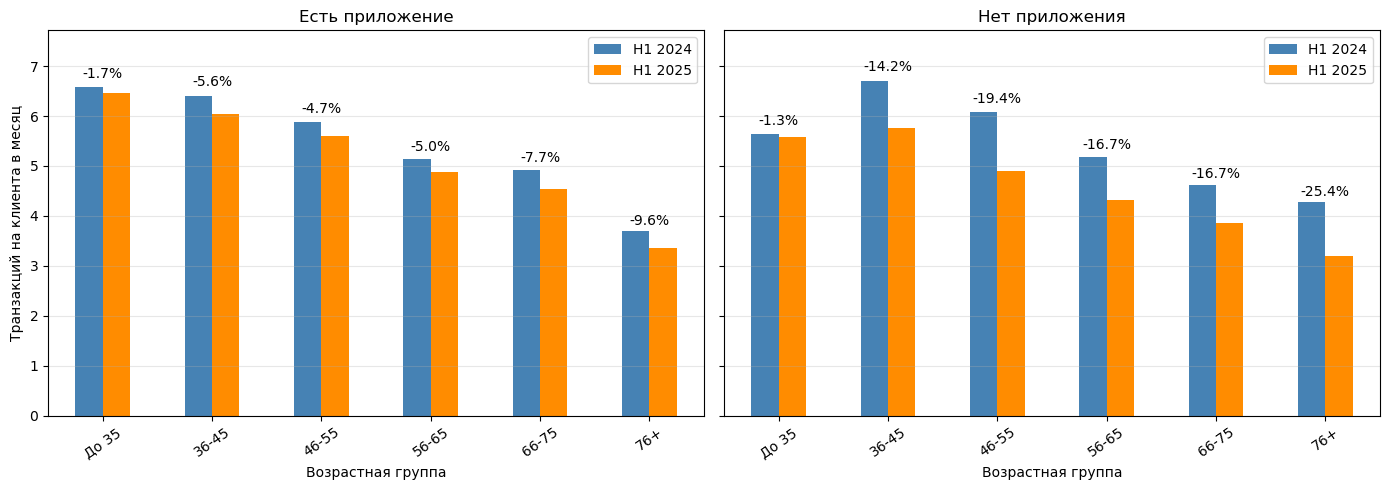

In [114]:
client_change["age_group"] = pd.cut(
    (pd.Timestamp("2025-06-30") - client_change["birth_date"]).dt.days / 365.2425,
    bins=[0, 35, 45, 55, 65, 75, np.inf],
    labels=["До 35", "36-45", "46-55", "56-65", "66-75", "76+"],
)

age_app = client_change.groupby(
    ["age_group", "has_mobile_app"], observed=True
)[["h1_2024_monthly_transactions", "h1_2025_monthly_transactions"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, app_value, title in zip(
    axes,
    ["Да", "Нет"],
    ["Есть приложение", "Нет приложения"],
):
    data = age_app.xs(app_value, level="has_mobile_app")
    data.columns = ["H1 2024", "H1 2025"]
    data.plot.bar(ax=ax, color=["steelblue", "darkorange"])

    change_pct = (data["H1 2025"] / data["H1 2024"] - 1) * 100
    for position, change in enumerate(change_pct):
        height = data.iloc[position].max()
        ax.text(position, height * 1.03, f"{change:+.1f}%", ha="center")

    ax.set_title(title)
    ax.set_xlabel("Возрастная группа")
    ax.set_ylabel("Транзакций на клиента в месяц")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.15)

plt.tight_layout()
plt.show()

#### Сегмент и категория покупки

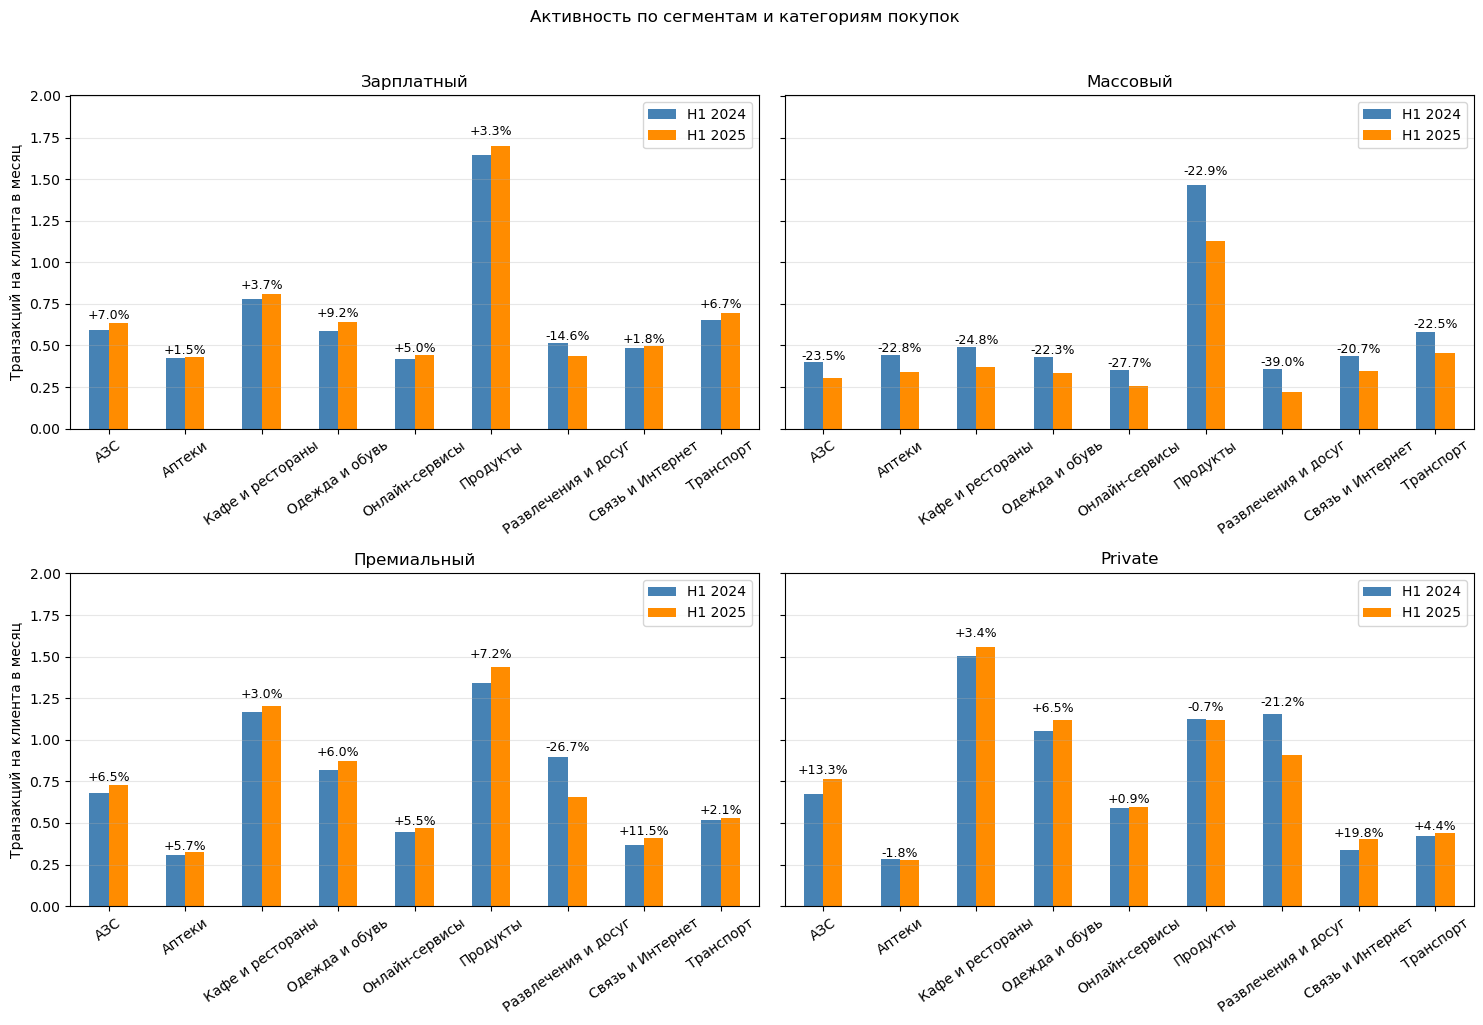

In [115]:
client_segments = comparison_clients[["client_id", "segment"]]

h1_2024_segment = h1_2024_txn.merge(client_segments, on="client_id")
h1_2025_segment = h1_2025_txn.merge(client_segments, on="client_id")

segments = comparison_clients["segment"].dropna().unique()
categories = sorted(comparison_txn["category"].dropna().unique())

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)

for ax, segment in zip(axes.flat, segments):
    clients_count = (comparison_clients["segment"] == segment).sum()

    data = pd.DataFrame({
        "H1 2024": h1_2024_segment.loc[
            h1_2024_segment["segment"] == segment, "category"
        ].value_counts(),
        "H1 2025": h1_2025_segment.loc[
            h1_2025_segment["segment"] == segment, "category"
        ].value_counts(),
    }).reindex(categories).fillna(0) / clients_count / 6

    data.plot.bar(ax=ax, color=["steelblue", "darkorange"])

    change_pct = (data["H1 2025"] / data["H1 2024"] - 1) * 100
    for position, change in enumerate(change_pct):
        height = data.iloc[position].max()
        ax.text(position, height * 1.04, f"{change:+.1f}%", ha="center", fontsize=9)

    ax.set_title(segment)
    ax.set_xlabel("")
    ax.set_ylabel("Транзакций на клиента в месяц")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.18)

plt.suptitle("Активность по сегментам и категориям покупок", y=1.02)
plt.tight_layout()
plt.show()

#### Уровень лояльности и наличие приложения

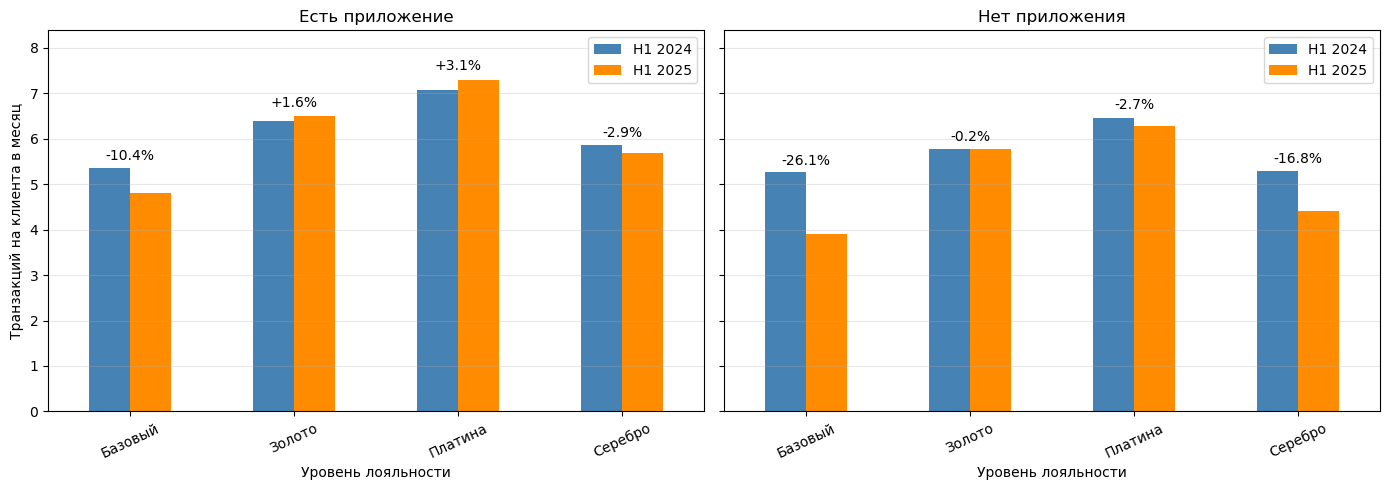

In [116]:
loyalty_app = client_change.groupby(
    ["loyalty_tier", "has_mobile_app"], observed=True
)[["h1_2024_monthly_transactions", "h1_2025_monthly_transactions"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, app_value, title in zip(
    axes,
    ["Да", "Нет"],
    ["Есть приложение", "Нет приложения"],
):
    data = loyalty_app.xs(app_value, level="has_mobile_app").copy()
    data.columns = ["H1 2024", "H1 2025"]
    data.plot.bar(ax=ax, color=["steelblue", "darkorange"])

    change_pct = (data["H1 2025"] / data["H1 2024"] - 1) * 100
    for position, change in enumerate(change_pct):
        height = data.iloc[position].max()
        ax.text(position, height * 1.03, f"{change:+.1f}%", ha="center")

    ax.set_title(title)
    ax.set_xlabel("Уровень лояльности")
    ax.set_ylabel("Транзакций на клиента в месяц")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)
    ax.margins(y=0.15)

plt.tight_layout()
plt.show()

Снижение видно в большинстве рассмотренных групп. Сильнее всего оно выражено в массовом сегменте, особенно среди клиентов без приложения. По категориям падение не ограничивается одним видом покупок. Рост операций через токен компенсирует только часть снижения остальных каналов.

В массовом сегменте снизились все категории покупок. Сильнее всего сократились развлечения и досуг (−39,0%), онлайн-сервисы (−27,7%) и кафе и рестораны (−24,8%). В зарплатном и премиальном сегментах большинство категорий, наоборот, выросло, но операции в категории развлечений и досуга также снизились.

Связь с приложением различается по уровню лояльности. Самое заметное снижение наблюдается у клиентов базового уровня без приложения (−26,1%). У клиентов без приложения с золотым и платиновым уровнем активность почти не изменилась. Значит, отсутствие приложения связано с сильным снижением не у всех клиентов, а прежде всего у групп с более низким уровнем лояльности. Эти связи не доказывают причину снижения, но помогают выделить группы для дальнейшей проверки.

#### Использование токена по сегментам

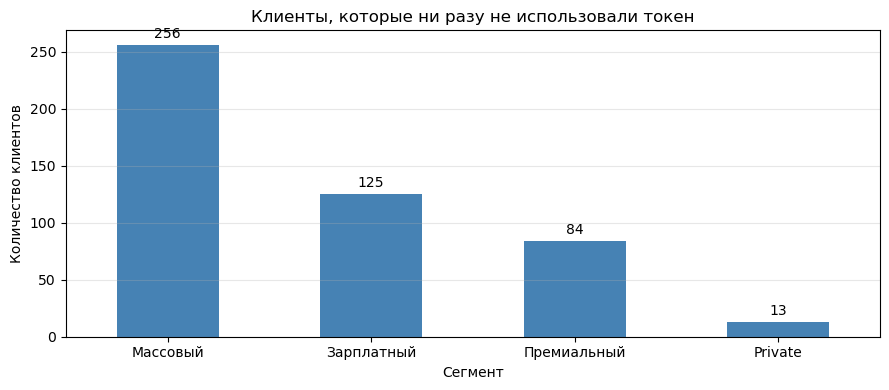

In [117]:
token_clients = comparison_txn.loc[
    comparison_txn["channel"] == "Токен", "client_id"
].unique()

token_usage = comparison_clients[["client_id", "segment"]].copy()
token_usage["used_token"] = token_usage["client_id"].isin(token_clients)

never_token_by_segment = (
    token_usage.loc[~token_usage["used_token"], "segment"]
    .value_counts()
    .sort_values(ascending=False)
)

ax = never_token_by_segment.plot.bar(figsize=(9, 4), color="steelblue")
ax.set_title("Клиенты, которые ни разу не использовали токен")
ax.set_xlabel("Сегмент")
ax.set_ylabel("Количество клиентов")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], padding=3)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [118]:
token_summary = pd.DataFrame({
    "Показатель": [
        "Всего клиентов в сопоставимой группе",
        "Хотя бы раз использовали токен",
        "Ни разу не использовали токен",
    ],
    "Клиентов": [
        len(token_usage),
        token_usage["used_token"].sum(),
        (~token_usage["used_token"]).sum(),
    ],
})
token_summary["Доля от 5 527 клиентов, %"] = (
    token_summary["Клиентов"] / len(token_usage) * 100
)

display(token_summary.round(2))

,Показатель,Клиентов,"Доля от 5 527 клиентов, %"
0,Всего клиентов в сопоставимой группе,5527,100.00
1,Хотя бы раз использовали токен,5049,91.35
2,Ни разу не использовали токен,478,8.65


Ниже сравниваются клиенты, использовавшие токен хотя бы один раз, и клиенты, не использовавшие его ни разу.

In [119]:
operations_by_client = (
    comparison_txn.groupby("client_id").size()
    .reindex(token_usage["client_id"], fill_value=0)
)

token_activity = token_usage.set_index("client_id").copy()
token_activity["operations"] = operations_by_client
token_activity["operations_per_month"] = token_activity["operations"] / 18
token_activity["Группа"] = np.where(
    token_activity["used_token"],
    "Использовали токен",
    "Ни разу не использовали токен",
)

token_activity_summary = token_activity.groupby("Группа").agg(
    Клиентов=("operations", "size"),
    **{
        "Среднее операций на клиента за 18 месяцев": ("operations", "mean"),
        "Среднее операций на клиента в месяц": ("operations_per_month", "mean"),
    },
)

display(token_activity_summary.round(2))

,Клиентов,Среднее операций на клиента за 18 месяцев,Среднее операций на клиента в месяц
Группа,,,
Использовали токен,5049,110.38,6.13
Ни разу не использовали токен,478,32.15,1.79


Использование токена внутри возрастных групп:

In [120]:
token_age = token_usage.merge(
    comparison_clients[["client_id", "birth_date"]],
    on="client_id",
    how="left",
)
token_age["age_group"] = pd.cut(
    (pd.Timestamp("2025-06-30") - token_age["birth_date"]).dt.days / 365.2425,
    bins=[0, 35, 45, 55, 65, 75, np.inf],
    labels=["До 35", "36-45", "46-55", "56-65", "66-75", "76+"],
)

token_age_summary = token_age.groupby("age_group", observed=True).agg(
    **{
        "Всего клиентов": ("client_id", "size"),
        "Использовали токен": ("used_token", "sum"),
    }
)
token_age_summary["Не использовали токен"] = (
    token_age_summary["Всего клиентов"] - token_age_summary["Использовали токен"]
)
token_age_summary["Доля использовавших токен внутри группы, %"] = (
    token_age_summary["Использовали токен"]
    / token_age_summary["Всего клиентов"] * 100
)

display(token_age_summary.round(2))

,Всего клиентов,Использовали токен,Не использовали токен,"Доля использовавших токен внутри группы, %"
age_group,,,,
До 35,377,371,6,98.41
36-45,1260,1214,46,96.35
46-55,1579,1428,151,90.44
56-65,1172,1034,138,88.23
66-75,664,582,82,87.65
76+,475,420,55,88.42


процентое соотношение использовавших токен хоть раз достаточно большое у всех возрастов

## 6. Метрика активности

В качестве метрики активности выбрано **среднее количество успешных транзакций клиента в месяц**.

Чтобы сезонность не искажала результат, сравниваются одинаковые календарные периоды: январь-июнь 2024 года и январь-июнь 2025 года. В обоих случаях число успешных транзакций клиента делится на 6 месяцев.

Сравнение проводится по одной и той же группе клиентов, зарегистрированных до 01.01.2024. В расчёт включены все клиенты этой группы, в том числе клиенты с нулём операций в одном из периодов. Затем результат усредняется по группе.

Метрика показывает частоту использования карт банка. Она не отражает сумму покупок, прибыль банка и операции клиента в других банках.

In [121]:
base_start = pd.Timestamp("2024-01-01")
base_end = pd.Timestamp("2024-07-01")
evaluation_start = pd.Timestamp("2025-01-01")
evaluation_end = pd.Timestamp("2025-07-01")
base_months = 6
evaluation_months = 6

final_cohort = clients.loc[clients["registration_date"] < base_start].copy()

final_txn = txn.loc[
    txn["client_id"].isin(final_cohort["client_id"])
    & (txn["txn_datetime"] >= base_start)
    & (txn["txn_datetime"] < evaluation_end)
].copy()

# Метрика пункта 6: одинаковые полугодия.
h1_2024_counts = (
    final_txn.loc[final_txn["txn_datetime"] < "2024-07-01"]
    .groupby("client_id").size()
)
h1_2025_counts = (
    final_txn.loc[final_txn["txn_datetime"] >= "2025-01-01"]
    .groupby("client_id").size()
)

metric_activity = final_cohort[["client_id"]].copy()
metric_activity["h1_2024_monthly"] = (
    metric_activity["client_id"].map(h1_2024_counts).fillna(0) / 6
)
metric_activity["h1_2025_monthly"] = (
    metric_activity["client_id"].map(h1_2025_counts).fillna(0) / 6
)

activity_metric = pd.DataFrame({
    "Январь-июнь 2024": [metric_activity["h1_2024_monthly"].mean()],
    "Январь-июнь 2025": [metric_activity["h1_2025_monthly"].mean()],
}, index=["Успешных транзакций на клиента в месяц"])
activity_metric["Изменение, %"] = (
    activity_metric["Январь-июнь 2025"]
    / activity_metric["Январь-июнь 2024"] - 1
) * 100

display(activity_metric.round(2))

# Расчёты ниже используются дальше при формировании групп кампании.
base_counts = (
    final_txn.loc[final_txn["txn_datetime"] < base_end]
    .groupby("client_id").size()
)
evaluation_counts = (
    final_txn.loc[final_txn["txn_datetime"] >= evaluation_start]
    .groupby("client_id").size()
)

client_activity = final_cohort.copy()
client_activity["base_monthly_transactions"] = (
    client_activity["client_id"].map(base_counts).fillna(0) / base_months
)
client_activity["evaluation_monthly_transactions"] = (
    client_activity["client_id"].map(evaluation_counts).fillna(0) / evaluation_months
)
client_activity["monthly_change"] = (
    client_activity["evaluation_monthly_transactions"]
    - client_activity["base_monthly_transactions"]
)
client_activity["relative_change_pct"] = np.where(
    client_activity["base_monthly_transactions"] > 0,
    client_activity["monthly_change"]
    / client_activity["base_monthly_transactions"] * 100,
    np.nan,
)
client_activity["declined"] = client_activity["monthly_change"] < 0
client_activity["stopped"] = (
    (client_activity["base_monthly_transactions"] > 0)
    & (client_activity["evaluation_monthly_transactions"] == 0)
)
client_activity["gross_monthly_loss"] = (
    -client_activity["monthly_change"]
).clip(lower=0)

,Январь-июнь 2024,Январь-июнь 2025,"Изменение, %"
Успешных транзакций на клиента в месяц,5.63,5.08,-9.76


In [122]:
all_2024_counts = (
    final_txn.loc[final_txn["txn_datetime"] < "2025-01-01"]
    .groupby("client_id").size()
)

stopped_count = int((
    (final_cohort["client_id"].map(all_2024_counts).fillna(0) > 0)
    & (final_cohort["client_id"].map(h1_2025_counts).fillna(0) == 0)
).sum())
stopped_share = stopped_count / len(final_cohort) * 100

print(
    f"Были операции в 2024 году, но не в H1 2025: {stopped_count} "
    f"из {len(final_cohort)} клиентов ({stopped_share:.2f}%)."
)


Были операции в 2024 году, но не в H1 2025: 6 из 5527 клиентов (0.11%).


6 из 5 527 клиентов (0,11%) совершали успешные операции хотя бы раз за 2024 год, но не совершили ни одной в первом полугодии 2025 года.

## 7. Поиск и описание групп

**Сегмент и наличие приложения.** Для каждой строки рассчитано среднее число операций на клиента в месяц. В последнем столбце показано число клиентов, у которых активность снизилась и есть согласие на коммуникацию.

In [123]:
campaign_base = clients.loc[
    clients["registration_date"] < "2024-01-01"
].set_index("client_id").copy()

campaign_transactions = txn.loc[
    txn["client_id"].isin(campaign_base.index)
].copy()
campaign_transactions["day"] = campaign_transactions["txn_datetime"].dt.normalize()

base_transactions = campaign_transactions.loc[
    campaign_transactions["txn_datetime"].between(
        "2024-01-01", "2024-07-01", inclusive="left"
    )
]
current_transactions = campaign_transactions.loc[
    campaign_transactions["txn_datetime"].between(
        "2025-01-01", "2025-07-01", inclusive="left"
    )
]

campaign_base["base_monthly"] = (
    base_transactions.groupby("client_id").size()
    .reindex(campaign_base.index, fill_value=0) / 6
)
campaign_base["current_monthly"] = (
    current_transactions.groupby("client_id").size()
    .reindex(campaign_base.index, fill_value=0) / 6
)
campaign_base["base_days"] = (
    base_transactions.groupby("client_id")["day"].nunique()
    .reindex(campaign_base.index, fill_value=0) / 6
)
campaign_base["current_days"] = (
    current_transactions.groupby("client_id")["day"].nunique()
    .reindex(campaign_base.index, fill_value=0) / 6
)
campaign_base["declined"] = (
    campaign_base["current_monthly"] < campaign_base["base_monthly"]
)
campaign_base["eligible"] = (
    campaign_base["declined"] & campaign_base["marketing_opt_in"].eq("Да")
)

segment_app_table = campaign_base.groupby(
    ["segment", "has_mobile_app"]
).agg(
    clients=("base_monthly", "size"),
    base=("base_monthly", "mean"),
    current=("current_monthly", "mean"),
    eligible=("eligible", "sum"),
)
segment_app_table["change_pct"] = (
    segment_app_table["current"] / segment_app_table["base"] - 1
) * 100

display(segment_app_table[[
    "clients", "base", "current", "change_pct", "eligible"
]].rename(columns={
    "clients": "Клиентов, n",
    "base": "Первое полугодие 2024, операций на клиента в месяц",
    "current": "Первое полугодие 2025, операций на клиента в месяц",
    "change_pct": "Изменение относительно первого полугодия 2024, %",
    "eligible": "Со снижением и согласием, n",
}).round(2))

Клиентов, n  Первое полугодие 2024, операций на клиента в месяц  Первое полугодие 2025, операций на клиента в месяц  \
segment     has_mobile_app                                                                                                                        
Private     Да                      132                                               8.03                                                8.02    
            Нет                      91                                               5.87                                                5.99    
Зарплатный  Да                      920                                               6.31                                                6.60    
            Нет                     639                                               5.80                                                5.83    
Массовый    Да                     1740                                               5.00                                                4.18    
            Нет                    1084                                               4.90                                                3.06    
Премиальный Да                      583                                               6.74                                                7.02    
            Нет                     338                                               6.23                                                5.96    

                            Изменение относительно первого полугодия 2024, %  Со снижением и согласием, n  
segment     has_mobile_app                                                                                 
Private     Да                                                         -0.16                           58  
            Нет                                                         2.09                           39  
Зарплатный  Да                                                          4.60                          328  
            Нет                                                         0.54                          231  
Массовый    Да                                                        -16.29                          877  
            Нет                                                       -37.52                          717  
Премиальный Да                                                          4.17                          201  
            Нет                                                        -4.24                          144

Сильнее всего средняя активность снизилась в массовом сегменте: на 37,52% без приложения и на 16,29% с приложением.

**Категории покупок.** Для каждой категории рассчитано число операций на одного клиента сопоставимой группы в месяц. В знаменателе остаются все 5 527 клиентов, включая тех, у кого не было покупок в категории.

In [124]:
base_category_counts = (
    base_transactions.groupby(["client_id", "category"]).size()
    .unstack(fill_value=0).reindex(campaign_base.index, fill_value=0)
)
current_category_counts = (
    current_transactions.groupby(["client_id", "category"]).size()
    .unstack(fill_value=0).reindex_like(base_category_counts).fillna(0)
)

category_table = pd.DataFrame({
    "Первое полугодие 2024, операций на клиента в месяц": base_category_counts.sum() / len(campaign_base) / 6,
    "Первое полугодие 2025, операций на клиента в месяц": current_category_counts.sum() / len(campaign_base) / 6,
})
category_table["Изменение относительно первого полугодия 2024, %"] = (
    category_table.iloc[:, 1] / category_table.iloc[:, 0] - 1
) * 100
display(category_table.sort_values("Изменение относительно первого полугодия 2024, %").round(2))

,"Первое полугодие 2024, операций на клиента в месяц","Первое полугодие 2025, операций на клиента в месяц","Изменение относительно первого полугодия 2024, %"
category,,,
Развлечения и досуг,0.52,0.38,-27.17
Аптеки,0.41,0.36,-11.49
Онлайн-сервисы,0.40,0.36,-10.06
Продукты,1.48,1.34,-9.48
Транспорт,0.59,0.53,-8.90
Связь и Интернет,0.44,0.40,-7.81
Кафе и рестораны,0.73,0.68,-6.35
АЗС,0.51,0.49,-4.95
Одежда и обувь,0.56,0.54,-4.03


Снижение есть во всех девяти категориях. Сильнее всего сократились развлечения и досуг.

**Категория, сегмент и наличие приложения.** Для каждой группы показаны изменение количества операций в процентах и изменение среднего количества операций в месяц. Размер группы указан в заголовке как n.

In [125]:
segment_order = ["Массовый", "Зарплатный", "Премиальный", "Private"]
app_order = ["Да", "Нет"]
profile = (
    campaign_base["segment"].astype("string")
    + ", приложение: "
    + campaign_base["has_mobile_app"].str.lower()
)
profile_order = [
    f"{segment}, приложение: {app.lower()}"
    for segment in segment_order for app in app_order
]
profile_sizes = profile.value_counts()

base_category_by_profile = base_category_counts.groupby(profile).sum() / 6
current_category_by_profile = current_category_counts.groupby(profile).sum() / 6

segment_category_app_table = (
    (current_category_by_profile / base_category_by_profile - 1) * 100
).T.reindex(columns=profile_order)
category_operations_change = (
    current_category_by_profile - base_category_by_profile
).T.reindex(columns=profile_order)

category_table_for_display = pd.DataFrame(index=segment_category_app_table.index)
for client_group in profile_order:
    group_name = f"{client_group} (n={profile_sizes[client_group]})"
    category_table_for_display[(group_name, "Изменение относительно первого полугодия 2024, %")] = (
        segment_category_app_table[client_group].round(1)
    )
    category_table_for_display[(group_name, "Изменение, операций в месяц")] = (
        category_operations_change[client_group].round(1)
    )

category_table_for_display.columns = pd.MultiIndex.from_tuples(
    category_table_for_display.columns
)
display(category_table_for_display)

Массовый, приложение: да (n=1740)                                           Массовый, приложение: нет (n=1084)  \
                    Изменение относительно первого полугодия 2024, % Изменение, операций в месяц Изменение относительно первого полугодия 2024, %   
category                                                                                                                                            
АЗС                                                            -16.7                      -118.0                                            -34.9   
Аптеки                                                         -15.0                      -115.8                                            -35.3   
Кафе и рестораны                                               -15.7                      -133.0                                            -39.2   
Одежда и обувь                                                 -14.3                      -108.8                                            -35.6   
Онлайн-сервисы                                                 -19.6                      -121.3                                            -40.8   
Продукты                                                       -15.3                      -395.0                                            -35.6   
Развлечения и досуг                                            -30.4                      -185.7                                            -52.0   
Связь и Интернет                                               -12.2                       -94.5                                            -34.8   
Транспорт                                                      -14.1                      -144.5                                            -36.3   

                                                              Зарплатный, приложение: да (n=920)                              \
                    Изменение, операций в месяц Изменение относительно первого полугодия 2024, % Изменение, операций в месяц   
category                                                                                                                       
АЗС                                      -147.5                                              8.9                        50.0   
Аптеки                                   -168.0                                              3.8                        15.3   
Кафе и рестораны                         -211.0                                              4.5                        33.3   
Одежда и обувь                           -161.7                                             14.1                        78.5   
Онлайн-сервисы                           -156.0                                              6.3                        25.0   
Продукты                                 -553.0                                              2.9                        45.8   
Развлечения и досуг                      -209.8                                            -12.5                       -60.2   
Связь и Интернет                         -161.0                                              5.5                        25.7   
Транспорт                                -226.2                                              8.6                        53.3   

                                 Зарплатный, приложение: нет (n=639)                                          Премиальный, приложение: да (n=583)  \
                    Изменение относительно первого полугодия 2024, % Изменение, операций в месяц Изменение относительно первого полугодия 2024, %   
category                                                                                                                                            
АЗС                                                              4.0                        14.7                                              8.0   
Аптеки                                                          -2.2                        -5.5                 

**Сегмент, наличие приложения и способ оплаты.** По строкам расположены способы оплаты. Для каждой группы клиентов сделаны два соседних столбца: изменение количества операций в процентах и изменение среднего количества операций в месяц в штуках

In [126]:
channel_order = ["Карта", "СБП", "Токен", "Онлайн-банк"]

base_channel_counts = (
    base_transactions.groupby(["client_id", "channel"]).size()
    .unstack(fill_value=0).reindex(campaign_base.index, fill_value=0)
)
current_channel_counts = (
    current_transactions.groupby(["client_id", "channel"]).size()
    .unstack(fill_value=0).reindex_like(base_channel_counts).fillna(0)
)

base_channel_by_profile = base_channel_counts.groupby(profile).sum() / 6
current_channel_by_profile = current_channel_counts.groupby(profile).sum() / 6

segment_channel_table = (
    (current_channel_by_profile / base_channel_by_profile - 1) * 100
).T.reindex(index=channel_order, columns=profile_order)
channel_operations_change = (
    current_channel_by_profile - base_channel_by_profile
).T.reindex(index=channel_order, columns=profile_order)

channel_table_for_display = pd.DataFrame(index=segment_channel_table.index)
for client_group in profile_order:
    group_name = f"{client_group} (n={profile_sizes[client_group]})"
    channel_table_for_display[(group_name, "Изменение относительно первого полугодия 2024, %")] = (
        segment_channel_table[client_group].round(1)
    )
    channel_table_for_display[(group_name, "Изменение, операций в месяц")] = (
        channel_operations_change[client_group].round(1)
    )

channel_table_for_display.columns = pd.MultiIndex.from_tuples(
    channel_table_for_display.columns
)
display(channel_table_for_display)

Массовый, приложение: да (n=1740)                                           Массовый, приложение: нет (n=1084)  \
            Изменение относительно первого полугодия 2024, % Изменение, операций в месяц Изменение относительно первого полугодия 2024, %   
channel                                                                                                                                     
Карта                                                  -32.8                     -1474.8                                            -36.1   
СБП                                                    -25.0                      -386.3                                            -47.4   
Токен                                                   43.0                       614.5                                            -33.0   
Онлайн-банк                                            -13.9                      -170.0                                            -35.5   

                                                      Зарплатный, приложение: да (n=920)                              \
            Изменение, операций в месяц Изменение относительно первого полугодия 2024, % Изменение, операций в месяц   
channel                                                                                                                
Карта                           -1123.8                                            -10.7                      -310.8   
СБП                              -406.2                                            -11.7                      -130.0   
Токен                            -171.5                                             68.6                       657.5   
Онлайн-банк                      -292.7                                              6.0                        50.2   

                         Зарплатный, приложение: нет (n=639)                                          Премиальный, приложение: да (n=583)  \
            Изменение относительно первого полугодия 2024, % Изменение, операций в месяц Изменение относительно первого полугодия 2024, %   
channel                                                                                                                                     
Карта                                                    2.6                        55.5                                            -17.5   
СБП                                                    -15.4                       -87.2                                             -5.5   
Токен                                                    8.4                        32.2                                             85.0   
Онлайн-банк                                              3.3                        19.5                                              7.4   

                                                    Премиальный, приложение: нет (n=338)                              \
            Изменение, операций в месяц Изменение относительно первого полугодия 2024, % Изменение, операций в месяц   
channel                                                                                                                
Карта                            -364.7                                             -4.5                       -54.8   
СБП                               -37.7                                            -11.2                       -39.8   
Токен                             525.8                                             -0.7                        -1.5   
Онлайн-банк                        40.2                                              2.1                         6.8   

                             Private, приложение: да (n=132)                                              Private, приложение: нет (n=91)  \
            Изменение относительно первого полугодия 2024, % Изменение, операций в месяц Изменение относительно первого полугодия 2024, %   
channel                                                                                

Выделены четыре группы:

**Группа 1: массовые клиенты без приложения**, у которых между первыми полугодиями снизились общая активность и число дней с операциями.

**Группа 2: массовые клиенты с приложением**, у которых между первыми полугодиями снизились общая активность и число дней с операциями.

**Группа 3: премиальные клиенты**, у которых между первыми полугодиями снизились общая активность и операции в категории «Развлечения и досуг».

**Группа 4: зарплатные клиенты без приложения**, у которых между первыми полугодиями снизились общая активность и операции в категории «Продукты».


In [127]:
category_change = base_category_counts / 6 - current_category_counts / 6
eligible = campaign_base["marketing_opt_in"].eq("Да") & campaign_base["declined"]

group_masks = pd.DataFrame({
    "Группа 1": eligible & campaign_base["segment"].eq("Массовый")
          & campaign_base["has_mobile_app"].eq("Нет")
          & (campaign_base["current_days"] < campaign_base["base_days"]),
    "Группа 2": eligible & campaign_base["segment"].eq("Массовый")
          & campaign_base["has_mobile_app"].eq("Да")
          & (campaign_base["current_days"] < campaign_base["base_days"]),
    "Группа 3": eligible & campaign_base["segment"].eq("Премиальный")
          & category_change["Развлечения и досуг"].gt(0),
    "Группа 4": eligible & campaign_base["segment"].eq("Зарплатный")
          & campaign_base["has_mobile_app"].eq("Нет")
          & category_change["Продукты"].gt(0),
})

group_sizes = group_masks.sum()
group_count_table = group_sizes.rename("Клиентов, n").to_frame()
group_count_table.loc["Всего"] = group_sizes.sum()
display(group_count_table)

,"Клиентов, n"
Группа 1,706
Группа 2,845
Группа 3,258
Группа 4,162
Всего,1971


In [128]:
# итоговый список.
assert group_masks.sum(axis=1).le(1).all()

campaign_base["group"] = pd.Series(pd.NA, index=campaign_base.index, dtype="string")
for group in group_masks.columns:
    campaign_base.loc[group_masks[group], "group"] = group

campaign_candidates = campaign_base.loc[
    campaign_base["group"].notna()
].reset_index()

assert 3 <= len(group_sizes) <= 5
assert group_sizes.ge(150).all()
assert len(campaign_candidates) <= 2000
assert campaign_candidates["client_id"].is_unique
assert campaign_candidates["marketing_opt_in"].eq("Да").all()

Проверка гипотезы об укрупнении покупок.

In [129]:
rub_h1_2024 = h1_2024_txn.loc[h1_2024_txn["currency"] == "RUB"]
rub_h1_2025 = h1_2025_txn.loc[h1_2025_txn["currency"] == "RUB"]

spending_rows = []
for group, members in campaign_candidates.groupby("group"):
    client_ids = members["client_id"]
    amounts_2024 = rub_h1_2024.loc[
        rub_h1_2024["client_id"].isin(client_ids), "amount"
    ]
    amounts_2025 = rub_h1_2025.loc[
        rub_h1_2025["client_id"].isin(client_ids), "amount"
    ]

    metrics = {
        "Расходы на клиента в месяц, руб.": (
            amounts_2024.sum() / len(client_ids) / 6,
            amounts_2025.sum() / len(client_ids) / 6,
        ),
        "Средний чек, руб.": (amounts_2024.mean(), amounts_2025.mean()),
        "Медианный чек, руб.": (amounts_2024.median(), amounts_2025.median()),
    }

    for metric, (value_2024, value_2025) in metrics.items():
        spending_rows.append({
            "Группа": group,
            "Клиентов, n": len(client_ids),
            "Показатель": metric,
            "Январь-июнь 2024": value_2024,
            "Январь-июнь 2025": value_2025,
            "Изменение относительно января-июня 2024, %": (
                value_2025 / value_2024 - 1
            ) * 100,
        })

spending_comparison = pd.DataFrame(spending_rows)
display(spending_comparison.round(2))

,Группа,"Клиентов, n",Показатель,Январь-июнь 2024,Январь-июнь 2025,"Изменение относительно января-июня 2024, %"
0,Группа 1,706,"Расходы на клиента в месяц, руб.",8523.66,3686.07,-56.75
1,Группа 1,706,"Средний чек, руб.",1573.87,1472.34,-6.45
2,Группа 1,706,"Медианный чек, руб.",937.19,859.96,-8.24
3,Группа 2,845,"Расходы на клиента в месяц, руб.",9129.72,5227.66,-42.74
4,Группа 2,845,"Средний чек, руб.",1522.17,1482.17,-2.63
5,Группа 2,845,"Медианный чек, руб.",913.64,859.03,-5.98
6,Группа 3,258,"Расходы на клиента в месяц, руб.",21405.19,12903.34,-39.72
7,Группа 3,258,"Средний чек, руб.",2616.49,2370.00,-9.42
8,Группа 3,258,"Медианный чек, руб.",1680.29,1431.70,-14.79
9,Группа 4,162,"Расходы на клиента в месяц, руб.",12505.32,6170.26,-50.66


Во всех четырёх группах снизились расходы на клиента в месяц, средний чек и медианный чек. Поэтому предположение, что клиенты просто объединили мелкие покупки в более крупные, не подтверждается.

### 7.1. Кто не включён в кампанию и почему

Все клиенты разделены по непересекающимся причинам исключения. Отдельно показано число клиентов, включённых в кампанию.

In [130]:
has_consent = campaign_base["marketing_opt_in"].eq("Да")
selected = campaign_base["group"].notna()

exclusion_reasons = pd.Series({
    "Нет полного базового периода": len(clients) - len(campaign_base),
    "Активность не снизилась": (~campaign_base["declined"]).sum(),
    "Активность снизилась, но нет согласия": (
        campaign_base["declined"] & ~has_consent
    ).sum(),
    "Есть снижение и согласие, но не подходят правила групп": (
        campaign_base["declined"] & has_consent & ~selected
    ).sum(),
}, dtype="int64")

exclusion_table = exclusion_reasons.rename("Клиентов, n").to_frame()
exclusion_table.loc["Всего не включены"] = exclusion_reasons.sum()
exclusion_table.loc["Включены в кампанию"] = selected.sum()
exclusion_table.loc["Всего клиентов"] = len(clients)

assert exclusion_reasons.sum() + selected.sum() == len(clients)
display(exclusion_table)

,"Клиентов, n"
Нет полного базового периода,133
Активность не снизилась,2555
"Активность снизилась, но нет согласия",377
"Есть снижение и согласие, но не подходят правила групп",624
Всего не включены,3689
Включены в кампанию,1971
Всего клиентов,5660


Не включены в кампанию:

клиентов без полного базового периода, без снижения активности или без согласия на коммуникацию;
клиентов со снижением и согласием, которые не подходят под правила групп.

Всего не включены 3 689 клиентов

## 8. Проверенные гипотезы

1. **Клиенты перенесли покупки в другой банк.** Проверить это нельзя: в двух исходных таблицах нет ни одного поля об операциях клиентов в других банках.
2. **Снижение связано только с декабрьским всплеском.** Не подтвердилось: при сравнении первых полугодий средняя активность 5 527 клиентов снизилась с 5,63 до 5,08 операции на клиента в месяц.
3. **Клиенты полностью перестали пользоваться картами банка.** Не подтвердилось: 6 из 5 527 клиентов (0,11%) совершали успешные операции хотя бы раз за 2024 год, но не совершили ни одной в первом полугодии 2025 года.
4. **Клиенты стали реже платить, но объединили покупки в более крупные чеки.** Не подтвердилось: между первыми полугодиями расходы на одного клиента в месяц уменьшились в Группе 1 (n=706) на 4 837,59 руб., в Группе 2 (n=845) на 3 902,06 руб., в Группе 3 (n=258) на 8 501,85 руб., в Группе 4 (n=162) на 6 335,06 руб. Средний и медианный чеки также уменьшились.
5. **Общее снижение объясняется переходом на токен.** Не подтвердилось: между первыми полугодиями токен прибавил 1 772,50 операции в месяц, а карта, СБП и онлайн-банк вместе потеряли 4 812,67; рост токена компенсировал 36,8% этого сокращения.


## 9. Сохранение результатов

In [131]:
clean_data = txn.merge(
    clients, on="client_id", how="right", validate="many_to_one",
    suffixes=("_transaction", "_client"),
)
campaign_list = (
    campaign_candidates[["client_id", "group"]]
    .sort_values(["group", "client_id"])
    .reset_index(drop=True)
)

In [132]:
assert clean_data["client_id"].notna().all()
assert clean_data["client_id"].nunique() == len(clients)
assert campaign_list["client_id"].is_unique
assert len(campaign_list) <= 2000
assert campaign_list.groupby("group").size().min() >= 150

In [133]:
clean_data.to_csv("clean_data.csv", index=False, encoding="utf-8", date_format="%Y-%m-%d %H:%M:%S")
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign_list.to_csv("campaign_list.csv", index=False, encoding="utf-8")